# Process Capability Analysis: Port Louis Liquid-Fill Line (Spirulina Power)

**Ubuntu Naturals, Port Louis (Mauritius, Tier 2, Stage 4)** | Assignment A03 | Notebook by Abdoul Karim Savadogo (surname assumed; confirm before submitting)

> **Who did what.** *Built by Claude (AI assistant):* the code in every cell, the formulas for the control limits, capability indices, detectors and simulations, the figures, and a **first draft** of the narrative text, with every number in the text filled in from the executed code.
> *Yours to decide, check and rewrite in your own words:* the choice of baseline window (section 5.4), the false-alarm budget and capability target in the parameter cell, the reading of the capability numbers (section 6.4), the detector and threshold you would run (section 7.6), and the recommendations (section 8). These four cells are drafts, marked **DRAFT**, and the marking scheme rewards your own judgement there. You are responsible for every number and sentence you submit.

**The question.** The line now logs pasteuriser temperature every second and checks fill volume in subgroups of five. This notebook (1) explores and tests both datasets, (2) builds the control charts and capability indices in code, (3) prototypes an early-warning detector for the temperature series, and (4) tells the quality manager what to do and what automation adds.


## Contents
1. [Setup and parameters](#s1) 2. [Loading and checking the data](#s2) 3. [Exploratory analysis](#s3) 4. [Normality testing](#s4) 5. [Control charts](#s5) 6. [Capability of the fill process](#s6) 7. [Anomaly detection for the pasteuriser](#s7) 8. [Recommendations for the quality manager](#s8) 9. [What this notebook does not do](#s9)

*Every figure quoted in the text is printed by the last cell, so the narrative can be checked against the code.*

<a id="s1"></a>
## 1. Setup and parameters

The first cell lists the library versions and fixes one random seed (2026), so every simulation and bootstrap below repeats exactly. Every analysis choice sits in the parameter cell that follows, so another Ubuntu Naturals line can reuse the notebook by editing that cell and the two file names.

In [1]:
# Requirements: python >= 3.9, numpy, pandas, scipy, matplotlib, scikit-learn (all preinstalled on Google Colab).
# The notebook reads both CSVs by bare filename, so upload them beside it before "Run all".
import re, sys, time, json, math, platform, warnings
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from scipy import stats
from sklearn.ensemble import IsolationForest

warnings.filterwarnings("ignore")
%matplotlib inline

SEED = 2026                       # one fixed seed for every random draw in the notebook
rng = np.random.default_rng(SEED)
KEY = {}                          # every figure quoted in the narrative is stored here and printed in the last cell

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__, "| scikit-learn", sklearn.__version__)

COL = dict(blue="#1f4e79", red="#c0392b", amber="#e69f00", green="#2e7d32", grey="#7f7f7f", teal="#1b998b", purple="#6a4c93")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11, "axes.labelsize": 10, "legend.fontsize": 8,
                     "figure.autolayout": False})

python 3.14.4 | numpy 2.5.4 | pandas 3.1.1 | scipy 1.18.1 | matplotlib 3.11.2 | scikit-learn 1.9.1


All choices in one place. The ones that are judgement calls rather than arithmetic are the **baseline window** (readings 1 to 2,500, defended in section 5), the **false-alarm budget** (0.5 per hour, about one false alarm every two hours, an operator-tolerance choice), and the **capability target** (Cpk 1.33, a common customer requirement rather than a Port Louis rule).

In [2]:
# ---- every analysis choice lives here, so another line can reuse the notebook by changing this cell ----
TEMP_FILE = "A03_port_louis_pasteurisation_temp_10000.csv"
FILL_FILE = "A03_spirulina_fill_volume_200x5.csv"

BASELINE = (1, 2500)        # temperature readings (1-based, inclusive) used to FIT the control limits: the settled opening stretch
N_SUB = 5                   # fill-volume subgroup size
ZSCORE_WINDOW = 60          # seconds, rolling z-score window (from the brief)
K_CUSUM = 0.5               # CUSUM reference value, in sigma
FA_BUDGET_PER_HOUR = 0.5    # false-alarm budget for the temperature detectors: at most one false alarm per two hours
DEBOUNCE = 60               # seconds: alarms closer together than this count as ONE alarm episode
N_SIM = 200                 # simulated in-control runs per candidate threshold
SIM_LENGTH = 7200           # seconds per simulated run (two hours)
FAULT_START = 1800          # second at which simulated faults begin
TARGET_CPK = 1.33           # capability target for the fill process (judgement call, see section 7)
SENSOR_RESOLUTION = 0.1     # degrees C: the logger records one decimal place

# Control-chart constants for subgroup sizes 2-10:  n -> (A2, D3, D4, d2)
CONST = {2: (1.880, 0, 3.267, 1.128), 3: (1.023, 0, 2.574, 1.693), 4: (0.729, 0, 2.282, 2.059), 5: (0.577, 0, 2.114, 2.326),
         6: (0.483, 0, 2.004, 2.534), 7: (0.419, 0.076, 1.924, 2.704), 8: (0.373, 0.136, 1.864, 2.847),
         9: (0.337, 0.184, 1.816, 2.970), 10: (0.308, 0.223, 1.777, 3.078)}
D2_IMR, E2_IMR, D4_IMR = 1.128, 2.660, 3.267   # I-MR constants for moving ranges of 2 (E2 = 3/d2)
print("parameters set; baseline window = readings", BASELINE)

parameters set; baseline window = readings (1, 2500)


<a id="s2"></a>
## 2. Loading and checking the data

Both files start with comment lines carrying the specification, so the loader reads those lines separately and parses the limits from the header instead of typing them in. The raw tables are kept untouched; everything later uses copies.

In [3]:
def read_spc_csv(path):
    """Read a CSV whose first lines are '#' comments. Returns the data frame and the comment lines."""
    with open(path, encoding="utf-8") as fh:
        header = [ln.lstrip("# ").rstrip() for ln in fh if ln.startswith("#")]
    return pd.read_csv(path, comment="#"), header

def parse_spec(header, column):
    """Pull LSL, USL and target out of a header line such as 'X specification: 70.0-75.0 C (target 72.0 C)'."""
    for line in header:
        if column in line:
            m = re.search(r"specification: ([\d.]+)-([\d.]+) \S+ \(target ([\d.]+)", line)
            if m:
                return float(m.group(1)), float(m.group(2)), float(m.group(3))
    raise ValueError("no specification line for " + column)

temp_raw, temp_header = read_spc_csv(TEMP_FILE)
fill_raw, fill_header = read_spc_csv(FILL_FILE)
T_LSL, T_USL, T_TGT = parse_spec(temp_header, "Temperature_C")
F_LSL, F_USL, F_TGT = parse_spec(fill_header, "Fill_Volume_ml")
print("TEMPERATURE header:", *temp_header, sep="\n  ")
print("FILL VOLUME header:", *fill_header, sep="\n  ")
print(f"\nTemperature spec: {T_LSL}-{T_USL} C, target {T_TGT} C | Fill spec: {F_LSL}-{F_USL} ml, target {F_TGT} ml")

TEMPERATURE header:
  Ubuntu Naturals Port Louis liquid-fill line -- Spirulina Power pasteuriser
  IIoT temperature logging at 1-second intervals, 10,000 readings (~2h46m).
  Temperature_C specification: 70.0-75.0 C (target 72.0 C).
FILL VOLUME header:
  Ubuntu Naturals Port Louis liquid-fill line -- Spirulina Power liquid fill
  In-process fill-volume sampling, 200 subgroups of n=5 (1,000 bottles).
  Fill_Volume_ml specification: 490.0-510.0 ml (target 500.0 ml).

Temperature spec: 70.0-75.0 C, target 72.0 C | Fill spec: 490.0-510.0 ml, target 500.0 ml


In [4]:
# ---- completeness and sanity checks BEFORE trusting either file (the raw frames are never modified) ----
temp = temp_raw.copy(); fill = fill_raw.copy()
temp["Timestamp"] = pd.to_datetime(temp["Timestamp"]); fill["Timestamp"] = pd.to_datetime(fill["Timestamp"])
temp["t"] = np.arange(1, len(temp) + 1)                 # reading number = seconds since the first reading + 1

gaps = temp["Timestamp"].diff().dropna().dt.total_seconds()
decimals = temp_raw["Temperature_C"].astype(str).str.split(".").str[1].str.len()
sizes = fill.groupby("Subgroup").size()
sample_ok = fill.groupby("Subgroup")["Sample"].apply(lambda s: sorted(s) == list(range(1, N_SUB + 1))).all()

checks = pd.DataFrame({
    "temperature": {"rows": len(temp), "columns": temp.shape[1] - 1, "missing values": int(temp_raw.isna().sum().sum()),
                    "duplicate rows": int(temp_raw.duplicated().sum()), "duplicate timestamps": int(temp["Timestamp"].duplicated().sum()),
                    "gaps other than 1 s": int((gaps != 1).sum()), "distinct sensor ids": temp["Sensor_ID"].nunique(),
                    "readings outside spec": int(((temp.Temperature_C < T_LSL) | (temp.Temperature_C > T_USL)).sum()),
                    "decimal places used": int(decimals.max()), "min": temp.Temperature_C.min(), "max": temp.Temperature_C.max()},
    "fill volume": {"rows": len(fill), "columns": fill.shape[1], "missing values": int(fill_raw.isna().sum().sum()),
                    "duplicate rows": int(fill_raw.duplicated().sum()), "duplicate timestamps": int(fill["Timestamp"].duplicated().sum()),
                    "gaps other than 1 s": "n/a", "distinct sensor ids": "n/a",
                    "readings outside spec": int(((fill.Fill_Volume_ml < F_LSL) | (fill.Fill_Volume_ml > F_USL)).sum()),
                    "decimal places used": int(fill_raw["Fill_Volume_ml"].astype(str).str.split(".").str[1].str.len().max()),
                    "min": fill.Fill_Volume_ml.min(), "max": fill.Fill_Volume_ml.max()}})
display(checks)
print("\nfill: subgroups =", fill.Subgroup.nunique(), "| subgroup sizes =", sorted(sizes.unique()), "| samples numbered 1..5 in every subgroup =", bool(sample_ok),
      "| timestamps increasing =", bool(fill.Timestamp.is_monotonic_increasing))
print("fill operators:", fill.Operator.value_counts().to_dict())
KEY.update(t_rows=len(temp), f_rows=len(fill), f_groups=int(fill.Subgroup.nunique()), t_dups=int(temp_raw.duplicated().sum()),
           t_missing=int(temp_raw.isna().sum().sum()), f_missing=int(fill_raw.isna().sum().sum()), t_gaps=int((gaps != 1).sum()),
           t_max=float(temp.Temperature_C.max()), t_min=float(temp.Temperature_C.min()), f_over=int((fill.Fill_Volume_ml > F_USL).sum()),
           f_under=int((fill.Fill_Volume_ml < F_LSL).sum()), t_hours=float(len(temp) / 3600))

,temperature,fill volume
rows,10000.0,1000
columns,3.0,5
missing values,0.0,0
duplicate rows,0.0,0
duplicate timestamps,0.0,0
gaps other than 1 s,0.0,n/a
distinct sensor ids,1.0,n/a
readings outside spec,0.0,7
decimal places used,1.0,2
min,71.4,490.89



fill: subgroups = 200 | subgroup sizes = [np.int64(5)] | samples numbered 1..5 in every subgroup = True | timestamps increasing = True
fill operators: {'PN': 640, 'MB': 360}


**What the checks show.** The temperature file has 10,000 readings, exactly one second apart (0 gaps, 0 duplicates, 0 missing values), from one sensor, covering 2.78 hours. The fill file has 1,000 bottles in 200 subgroups of five, complete, with one operator per subgroup and a subgroup roughly every 10 minutes. Nothing needed cleaning, so **no value was changed, removed or imputed** (the cleaning decision is: leave everything as logged).

Two things to carry forward. First, the temperature logger records **one decimal place only** (0.1 C), and the normal spread of the series is about 0.15 C, so readings are coarse; section 4 shows what that does to normality tests. Second, **no temperature reading is outside the specification** (range 71.4 to 74.3 C against 70.0 to 75.0 C), while **7 bottles are above the 510 ml limit** (and none below 490 ml). A check against the specification limits alone would have raised no temperature alarm at all; the rest of this notebook is about what that hides.

In [5]:
# Fill volume as a 200 x 5 array (one row per subgroup), plus the operator and start time of each subgroup.
fill = fill.sort_values(["Subgroup", "Sample"]).reset_index(drop=True)
X = fill["Fill_Volume_ml"].to_numpy().reshape(-1, N_SUB)
sub = fill.groupby("Subgroup").agg(start=("Timestamp", "first"), operator=("Operator", "first"), n_ops=("Operator", "nunique")).reset_index()
sub["xbar"] = X.mean(axis=1); sub["R"] = X.max(axis=1) - X.min(axis=1)
x_temp = temp["Temperature_C"].to_numpy()
b0, b1 = BASELINE[0] - 1, BASELINE[1]
x_base = x_temp[b0:b1]
print("subgroups with more than one operator:", int((sub.n_ops > 1).sum()),
      "| spacing between subgroup starts (minutes): median", round(sub.start.diff().dt.total_seconds().median() / 60, 1))
print("baseline window:", len(x_base), "readings, from", temp.Timestamp.iloc[b0].time(), "to", temp.Timestamp.iloc[b1 - 1].time())

subgroups with more than one operator: 0 | spacing between subgroup starts (minutes): median 10.0
baseline window: 2500 readings, from 06:00:00 to 06:41:39


<a id="s3"></a>
## 3. Exploratory data analysis

For each dataset: descriptive statistics (mean, median, standard deviation, range, skewness, excess kurtosis), then multi-panel plots, then what they say. The temperature series is also summarised on its **baseline window** (readings 1 to 2,500), because the whole series mixes a steady process with two events, and a single set of numbers for all 10,000 readings would describe neither.

In [6]:
def describe(x):
    """The descriptive statistics the brief asks for."""
    x = np.asarray(x, float)
    return pd.Series({"n": len(x), "mean": x.mean(), "median": np.median(x), "std dev": x.std(ddof=1), "min": x.min(), "max": x.max(),
                      "range": np.ptp(x), "skewness": stats.skew(x), "excess kurtosis": stats.kurtosis(x)})

def acf(x, nlags):
    """Sample autocorrelation at lags 0..nlags."""
    x = np.asarray(x, float) - np.mean(x)
    return np.array([1.0] + [np.corrcoef(x[:-k], x[k:])[0, 1] for k in range(1, nlags + 1)])

desc = pd.DataFrame({"temperature, all readings (C)": describe(x_temp), "temperature, baseline window (C)": describe(x_base),
                     "fill volume, 1000 bottles (ml)": describe(fill.Fill_Volume_ml), "fill volume, 200 subgroup means (ml)": describe(sub.xbar)})
display(desc.round(3))

,"temperature, all readings (C)","temperature, baseline window (C)","fill volume, 1000 bottles (ml)","fill volume, 200 subgroup means (ml)"
n,10000.000,2500.000,1000.000,200.000
mean,72.289,71.998,500.914,500.914
median,72.100,72.000,500.905,500.967
std dev,0.589,0.149,3.157,1.451
min,71.400,71.500,490.890,497.306
max,74.300,72.500,513.500,506.454
range,2.900,1.000,22.610,9.148
skewness,1.615,-0.029,0.138,0.256
excess kurtosis,1.485,0.033,0.353,0.782


In [7]:
# ---- temperature: locate the events by code, not by eye ----
BASE_MU, BASE_SD = x_base.mean(), x_base.std(ddof=1)
roll30 = pd.Series(x_temp).rolling(30, center=True, min_periods=1).mean().to_numpy()
elevated = np.abs(roll30 - BASE_MU) > 0.75
elevated[7000:] = False                                  # the late drift is analysed separately below
ev_idx = np.where(elevated)[0]
ev_start, ev_end = int(ev_idx.min()) + 1, int(ev_idx.max()) + 1
ev_level = x_temp[ev_start + 30: ev_end - 30].mean()

def hinge_fit(y, t, lo, hi, step=10):
    """Fit y = a + s * max(0, t - tb) for the breakpoint tb that gives the smallest squared error."""
    best = None
    for tb in range(lo, hi, step):
        A = np.column_stack([np.ones_like(t, float), np.maximum(0, t - tb)])
        coef, res, *_ = np.linalg.lstsq(A, y, rcond=None)
        sse = ((y - A @ coef) ** 2).sum()
        if best is None or sse < best[0]:
            best = (sse, tb, coef[0], coef[1])
    return best

keep = np.ones(len(x_temp), bool); keep[ev_start - 30: ev_end + 30] = False
_, tb, a_hat, slope = hinge_fit(x_temp[keep], temp.t.to_numpy()[keep], 5000, 9500)
breach_t = tb + (T_USL - a_hat) / slope                   # when the fitted drift line would reach the upper spec limit
print(f"Event: readings {ev_start}-{ev_end} ({ev_end - ev_start + 1} s) at an average of {ev_level:.2f} C ({ev_level - BASE_MU:+.2f} C above baseline)")
print(f"Drift: starts near reading {tb}, rises {slope * 3600:.2f} C per hour ({slope:.5f} C per second); final reading {x_temp[-1]:.1f} C")
print(f"Fitted drift line reaches the {T_USL} C limit at reading {breach_t:,.0f}, i.e. {(breach_t - len(x_temp)) / 60:.0f} minutes after the data end")
KEY.update(base_mu=BASE_MU, base_sd=BASE_SD, ev_start=ev_start, ev_end=ev_end, ev_len=ev_end - ev_start + 1, ev_level=ev_level,
           drift_start=int(tb), drift_slope_hr=slope * 3600, drift_slope_s=slope, breach_t=float(breach_t), breach_after_min=(breach_t - len(x_temp)) / 60)

Event: readings 3014-3289 (276 s) at an average of 73.79 C (+1.79 C above baseline)
Drift: starts near reading 7600, rises 3.02 C per hour (0.00084 C per second); final reading 74.1 C
Fitted drift line reaches the 75.0 C limit at reading 11,180, i.e. 20 minutes after the data end


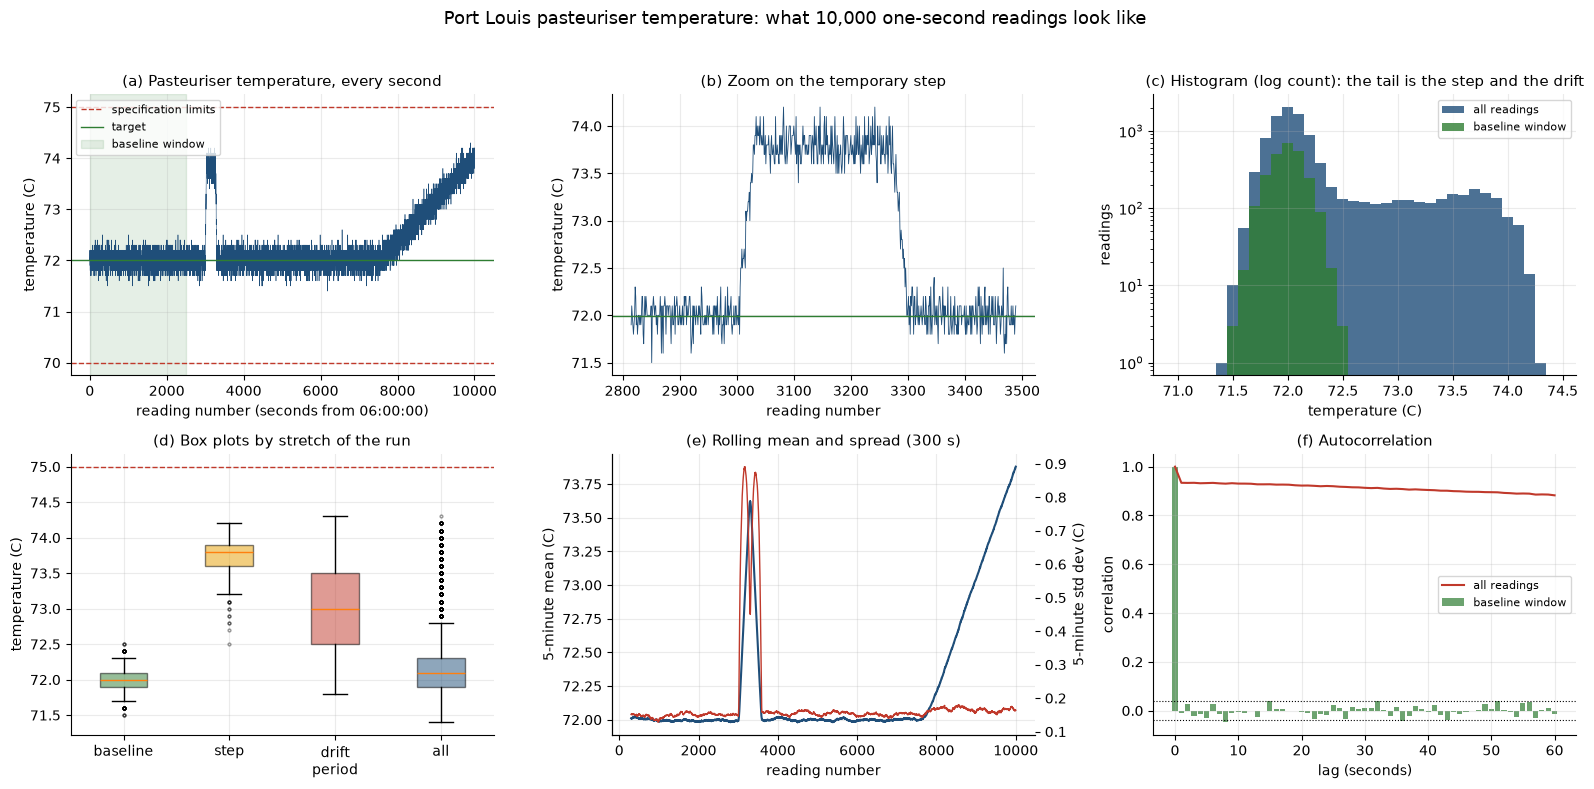

In [8]:
# ---- temperature: six-panel exploratory figure ----
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
a = ax[0, 0]; a.plot(temp.t, x_temp, lw=0.4, color=COL["blue"])
a.axhline(T_USL, color=COL["red"], ls="--", lw=1); a.axhline(T_LSL, color=COL["red"], ls="--", lw=1, label="specification limits")
a.axhline(T_TGT, color=COL["green"], lw=1, label="target"); a.axvspan(*BASELINE, color=COL["green"], alpha=0.12, label="baseline window")
a.set(title="(a) Pasteuriser temperature, every second", xlabel="reading number (seconds from 06:00:00)", ylabel="temperature (C)"); a.legend(loc="upper left")
a = ax[0, 1]; a.plot(temp.t[ev_start - 200: ev_end + 200], x_temp[ev_start - 201: ev_end + 199], lw=0.6, color=COL["blue"])
a.axhline(BASE_MU, color=COL["green"], lw=1); a.set(title="(b) Zoom on the temporary step", xlabel="reading number", ylabel="temperature (C)")
a = ax[0, 2]; a.hist(x_temp, bins=np.arange(70.95, 74.5, 0.1), color=COL["blue"], alpha=0.8, label="all readings")
a.hist(x_base, bins=np.arange(70.95, 74.5, 0.1), color=COL["green"], alpha=0.8, label="baseline window"); a.set_yscale("log")
a.set(title="(c) Histogram (log count): the tail is the step and the drift", xlabel="temperature (C)", ylabel="readings"); a.legend()
a = ax[1, 0]; bp = a.boxplot([x_base, x_temp[ev_start - 1: ev_end], x_temp[tb:], x_temp], tick_labels=["baseline", "step", "drift\nperiod", "all"], showfliers=True,
                              flierprops=dict(markersize=2, alpha=0.4), patch_artist=True)
for patch, c in zip(bp["boxes"], [COL["green"], COL["amber"], COL["red"], COL["blue"]]): patch.set_facecolor(c); patch.set_alpha(0.5)
a.axhline(T_USL, color=COL["red"], ls="--", lw=1); a.set(title="(d) Box plots by stretch of the run", ylabel="temperature (C)")
a = ax[1, 1]; r = pd.Series(x_temp).rolling(300)
a.plot(temp.t, r.mean(), color=COL["blue"], label="5-minute mean"); a.set_ylabel("5-minute mean (C)"); a2 = a.twinx(); a2.plot(temp.t, r.std(), color=COL["red"], lw=1, label="5-minute std dev")
a2.set_ylabel("5-minute std dev (C)"); a2.grid(False); a.set(title="(e) Rolling mean and spread (300 s)", xlabel="reading number")
a = ax[1, 2]; lags = np.arange(0, 61); a.bar(lags, acf(x_base, 60), color=COL["green"], alpha=0.7, label="baseline window")
a.plot(lags, acf(x_temp, 60), color=COL["red"], label="all readings"); a.axhline(1.96 / np.sqrt(len(x_base)), color="k", ls=":", lw=0.8); a.axhline(-1.96 / np.sqrt(len(x_base)), color="k", ls=":", lw=0.8)
a.set(title="(f) Autocorrelation", xlabel="lag (seconds)", ylabel="correlation"); a.legend()
fig.suptitle("Port Louis pasteuriser temperature: what 10,000 one-second readings look like", fontsize=13); plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()
KEY.update(acf1_base=float(acf(x_base, 1)[1]), acf1_all=float(acf(x_temp, 1)[1]), acf10_all=float(acf(x_temp, 10)[10]))

**Temperature: what the plots and tables show.**

* **A steady process, then two events.** In the baseline window the temperature averages 71.998 C with a standard deviation of 0.149 C, and is essentially symmetric (skewness -0.03, excess kurtosis 0.03). Over all readings the mean is 72.29 C, the standard deviation is 0.59 C (four times larger) and the distribution is skewed (skewness 1.62, kurtosis 1.49). The change in the statistics comes from the events, not from a change in the noise.
* **Event 1, a temporary step.** Found by code: from about reading 3014 to 3289 (276 seconds) the temperature sits near 73.79 C, about 1.8 C above baseline. It climbs over roughly 35 seconds (panel b), holds for about four and a half minutes, then falls back over a similar time. It stays inside the 70 to 75 C specification, so only a control chart or a detector would call it a problem.
* **Event 2, a slow drift.** From about reading 7,600 the temperature rises steadily at 3.02 C per hour (0.00084 C per second), found by fitting a straight line that bends at the best-fitting breakpoint. The last readings are near 74 C and the maximum is 74.3 C. If the fitted line continued, it would reach the 75 C limit about 20 minutes after the data end (a straight-line extrapolation, not a forecast; real equipment would not necessarily keep drifting).
* **Time pattern.** In the 500-second block table, 14 of 20 blocks are steady (block means within 0.1 C of baseline); the blocks that moved are the step block and the last five. The rolling 5-minute spread (panel e) is flat except during the step.
* **Autocorrelation.** In the baseline window consecutive readings are independent (lag-1 autocorrelation -0.008, inside the dotted 95% band), which is what the individuals chart assumes. Over the whole run lag-1 autocorrelation is 0.93 and stays high out to lag 10, because the events dominate: the series has memory only when something is moving.

**Hypotheses to test later:** (H1) limits fitted to all 10,000 readings will be contaminated by the events (section 5); (H2) a 60-second rolling z-score will adapt to a slow drift and miss it, while a cumulative-sum detector will not (section 7).

In [9]:
# 500-second block table: where does the series stop being steady?
blocks = pd.DataFrame({"from": np.arange(1, 10001, 500), "to": np.arange(500, 10001, 500)})
blocks["mean (C)"] = [x_temp[f - 1:t].mean() for f, t in zip(blocks["from"], blocks["to"])]
blocks["std dev (C)"] = [x_temp[f - 1:t].std(ddof=1) for f, t in zip(blocks["from"], blocks["to"])]
blocks["max (C)"] = [x_temp[f - 1:t].max() for f, t in zip(blocks["from"], blocks["to"])]
blocks["flag"] = np.where((blocks["mean (C)"] - BASE_MU).abs() > 0.1, "moved", "steady")
display(blocks.round(3).T)
KEY["n_blocks_steady"] = int((blocks.flag == "steady").sum())

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
from,1,501,1001,1501,2001,2501,3001,3501,4001,4501,5001,5501,6001,6501,7001,7501,8001,8501,9001,9501
to,500,1000,1500,2000,2500,3000,3500,4000,4500,5000,5500,6000,6500,7000,7500,8000,8500,9000,9500,10000
mean (C),72.008,71.999,71.995,71.991,71.997,71.989,72.972,72.008,71.992,72.003,72.0,71.996,71.995,71.998,72.002,72.14,72.54,72.966,73.385,73.8
std dev (C),0.152,0.136,0.152,0.15,0.153,0.148,0.874,0.159,0.153,0.153,0.159,0.151,0.153,0.147,0.154,0.182,0.197,0.188,0.18,0.191
max (C),72.5,72.4,72.5,72.4,72.5,72.4,74.2,72.5,72.5,72.5,72.4,72.5,72.4,72.6,72.4,72.7,73.2,73.5,73.9,74.3
flag,steady,steady,steady,steady,steady,steady,moved,steady,steady,steady,steady,steady,steady,steady,steady,moved,moved,moved,moved,moved


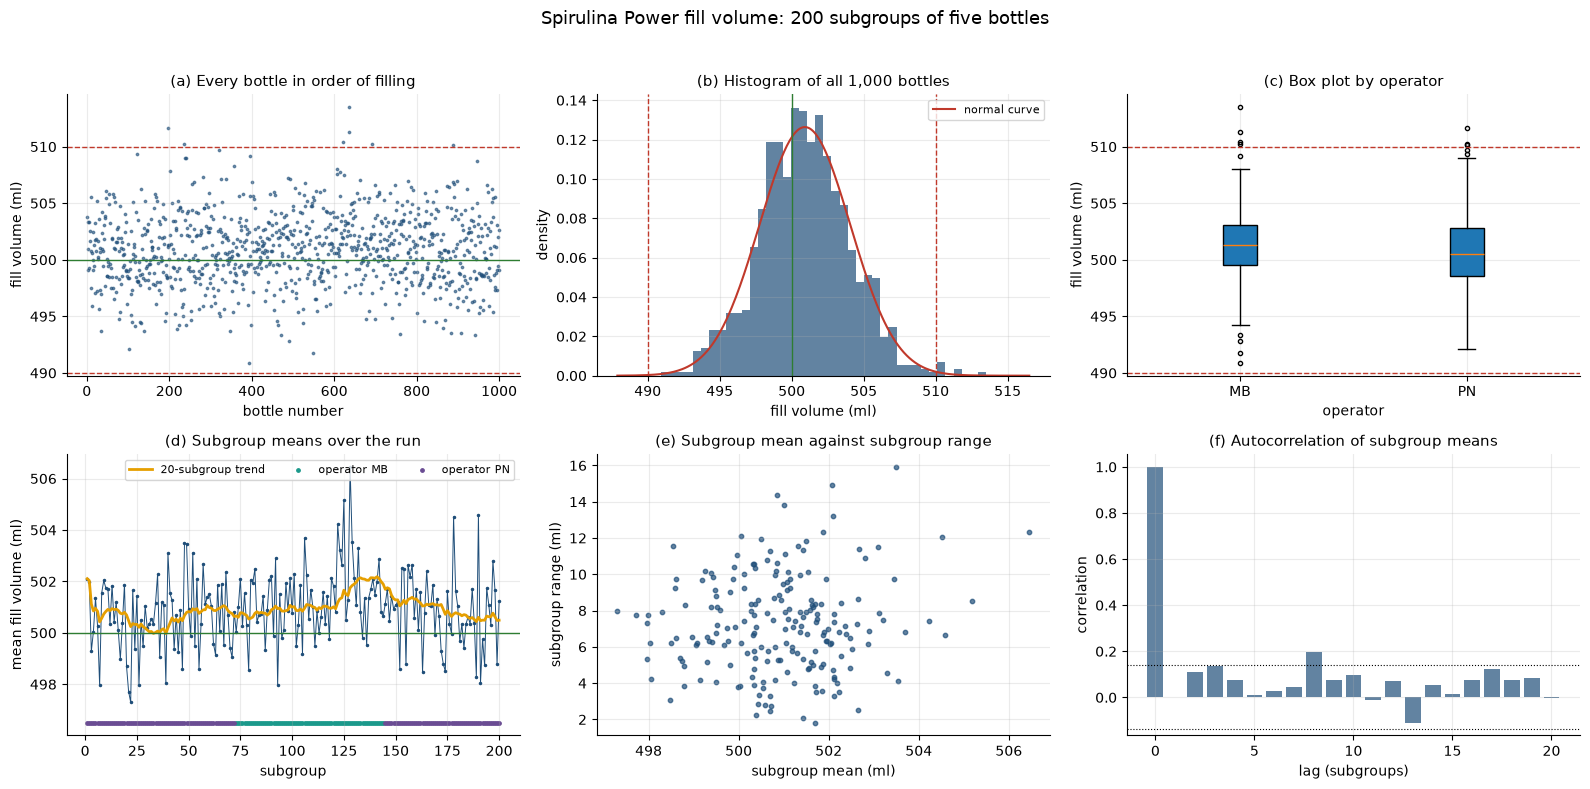

In [10]:
# ---- fill volume: six-panel exploratory figure ----
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
a = ax[0, 0]; a.scatter(np.arange(1, len(fill) + 1), fill.Fill_Volume_ml, s=3, color=COL["blue"], alpha=0.6)
a.axhline(F_USL, color=COL["red"], ls="--", lw=1); a.axhline(F_LSL, color=COL["red"], ls="--", lw=1); a.axhline(F_TGT, color=COL["green"], lw=1)
a.set(title="(a) Every bottle in order of filling", xlabel="bottle number", ylabel="fill volume (ml)")
a = ax[0, 1]; a.hist(fill.Fill_Volume_ml, bins=40, density=True, color=COL["blue"], alpha=0.7)
g = np.linspace(fill.Fill_Volume_ml.min() - 3, fill.Fill_Volume_ml.max() + 3, 300); a.plot(g, stats.norm.pdf(g, fill.Fill_Volume_ml.mean(), fill.Fill_Volume_ml.std(ddof=1)), color=COL["red"], label="normal curve")
a.axvline(F_USL, color=COL["red"], ls="--", lw=1); a.axvline(F_LSL, color=COL["red"], ls="--", lw=1); a.axvline(F_TGT, color=COL["green"], lw=1)
a.set(title="(b) Histogram of all 1,000 bottles", xlabel="fill volume (ml)", ylabel="density"); a.legend()
a = ax[0, 2]; ops = sorted(fill.Operator.unique()); a.boxplot([fill.Fill_Volume_ml[fill.Operator == o] for o in ops], tick_labels=ops, patch_artist=True, flierprops=dict(markersize=3))
a.axhline(F_USL, color=COL["red"], ls="--", lw=1); a.axhline(F_LSL, color=COL["red"], ls="--", lw=1); a.set(title="(c) Box plot by operator", xlabel="operator", ylabel="fill volume (ml)")
a = ax[1, 0]; a.plot(sub.Subgroup, sub.xbar, ".-", color=COL["blue"], lw=0.7, ms=3); a.plot(sub.Subgroup, sub.xbar.rolling(20, min_periods=1).mean(), color=COL["amber"], lw=2, label="20-subgroup trend")
for o, c in zip(ops, [COL["teal"], COL["purple"]]):
    a.scatter(sub.Subgroup[sub.operator == o], np.full((sub.operator == o).sum(), sub.xbar.min() - 0.8), s=6, color=c, label="operator " + o)
a.axhline(F_TGT, color=COL["green"], lw=1); a.set(title="(d) Subgroup means over the run", xlabel="subgroup", ylabel="mean fill volume (ml)"); a.legend(ncol=3)
a = ax[1, 1]; a.scatter(sub.xbar, sub.R, s=10, color=COL["blue"], alpha=0.7); a.set(title="(e) Subgroup mean against subgroup range", xlabel="subgroup mean (ml)", ylabel="subgroup range (ml)")
a = ax[1, 2]; lg = np.arange(0, 21); a.bar(lg, acf(sub.xbar, 20), color=COL["blue"], alpha=0.7); a.axhline(1.96 / np.sqrt(200), color="k", ls=":", lw=0.8); a.axhline(-1.96 / np.sqrt(200), color="k", ls=":", lw=0.8)
a.set(title="(f) Autocorrelation of subgroup means", xlabel="lag (subgroups)", ylabel="correlation")
fig.suptitle("Spirulina Power fill volume: 200 subgroups of five bottles", fontsize=13); plt.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()

In [11]:
r_xbar_R, p_xbar_R = stats.pearsonr(sub.xbar, sub.R)
w = stats.ttest_ind(sub.xbar[sub.operator == "PN"], sub.xbar[sub.operator == "MB"], equal_var=False)
wr = stats.ttest_ind(sub.R[sub.operator == "PN"], sub.R[sub.operator == "MB"], equal_var=False)
slope_f = stats.linregress(sub.Subgroup, sub.xbar)
op_runs = sub.assign(run=(sub.operator != sub.operator.shift()).cumsum()).groupby("run").agg(operator=("operator", "first"), first=("Subgroup", "min"), last=("Subgroup", "max"),
                                                                                         mean_ml=("xbar", "mean"), mean_range=("R", "mean"))
display(op_runs.round(2))
print(f"correlation of subgroup mean with subgroup range: r = {r_xbar_R:.3f} (p = {p_xbar_R:.2f})")
print(f"operator PN vs MB, subgroup means: {sub.xbar[sub.operator=='PN'].mean():.2f} vs {sub.xbar[sub.operator=='MB'].mean():.2f} ml, Welch t-test p = {w.pvalue:.3f}; ranges p = {wr.pvalue:.3f}")
print(f"trend of subgroup mean over the run: {slope_f.slope * 100:.3f} ml per 100 subgroups (p = {slope_f.pvalue:.2f}); lag-1 autocorrelation of subgroup means = {acf(sub.xbar, 1)[1]:.3f}")
pos = fill.groupby("Sample")["Fill_Volume_ml"].agg(["mean", "std"]); pos_p = stats.f_oneway(*[g.values for _, g in fill.groupby("Sample")["Fill_Volume_ml"]]).pvalue
display(pos.round(2).T); print(f"does sample position within the subgroup matter? one-way ANOVA p = {pos_p:.2f}")
KEY.update(f_op_diff=sub.xbar[sub.operator == 'MB'].mean() - sub.xbar[sub.operator == 'PN'].mean(), f_pos_p=pos_p, f_r_xbar_R=r_xbar_R, f_op_p=w.pvalue, f_op_range_p=wr.pvalue, f_pn_mean=sub.xbar[sub.operator == "PN"].mean(), f_mb_mean=sub.xbar[sub.operator == "MB"].mean(),
           f_slope_p=slope_f.pvalue, f_acf1=acf(sub.xbar, 1)[1], f_mean=fill.Fill_Volume_ml.mean(), f_sd=fill.Fill_Volume_ml.std(ddof=1),
           f_skew=stats.skew(fill.Fill_Volume_ml), f_kurt=stats.kurtosis(fill.Fill_Volume_ml), f_min=fill.Fill_Volume_ml.min(), f_max=fill.Fill_Volume_ml.max(),
           t_mean=x_temp.mean(), t_sd=x_temp.std(ddof=1), t_skew=stats.skew(x_temp), t_kurt=stats.kurtosis(x_temp), b_skew=stats.skew(x_base), b_kurt=stats.kurtosis(x_base))

,operator,first,last,mean_ml,mean_range
run,,,,,
1,PN,1,72,500.60,7.53
2,MB,73,144,501.32,7.02
3,PN,145,200,500.80,7.21


correlation of subgroup mean with subgroup range: r = 0.097 (p = 0.17)
operator PN vs MB, subgroup means: 500.69 vs 501.32 ml, Welch t-test p = 0.003; ranges p = 0.379
trend of subgroup mean over the run: 0.259 ml per 100 subgroups (p = 0.14); lag-1 autocorrelation of subgroup means = 0.003


Sample,1,2,3,4,5
mean,501.34,500.73,501.07,500.59,500.83
std,3.28,2.90,3.32,3.21,3.02


does sample position within the subgroup matter? one-way ANOVA p = 0.14


**Fill volume: what the plots and tables show.**

* **Centre and spread.** The 1,000 bottles average 500.91 ml (target 500 ml, so about 0.9 ml over on average) with a standard deviation of 3.16 ml, ranging from 490.89 to 513.5 ml. The distribution is close to symmetric (skewness 0.14, excess kurtosis 0.35), with a slightly heavy upper tail: the bottles above 510 ml are not rare.
* **Specification.** The limits are 490 to 510 ml, a spread of plus or minus 10 ml, which is only about 3.2 standard deviations either side of the mean. That is a tight fit, and the histogram (panel b) shows the right-hand tail touching the upper limit.
* **Operator effect (non-obvious).** Operator MB ran subgroups 73 to 144 and averaged 501.32 ml against 500.69 ml for PN, a difference of 0.63 ml that is unlikely to be chance (Welch t-test p = 0.003). The spread (range) does not differ (p = 0.38). Because the operators ran in blocks, an operator effect cannot be separated from a time effect (a set-up, product batch or filler setting that changed at the handover); that needs the shift log.
* **No trend, no memory.** The subgroup means show no significant trend over the run (p = 0.14), and consecutive subgroup means are uncorrelated (lag-1 autocorrelation 0.003), so the subgroups behave as independent samples. Subgroup mean and range are unrelated (r = 0.10), and the position of a bottle within its subgroup does not matter (ANOVA p = 0.14), so there is no sign of one filling head behaving differently.

**Hypotheses to test later:** (H3) the fill process is stable apart from a few outlying subgroups (section 5); (H4) the excess of bottles above 510 ml is more than a normal curve predicts (section 6).

<a id="s4"></a>
## 4. Normality testing

Control limits and capability indices both assume roughly normal data, so this is tested before it is relied on. Three tests are used: **Shapiro-Wilk** (for samples above 5,000 it is run on a random 5,000, the limit of the scipy implementation), **Anderson-Darling** (more sensitive to the tails; the statistic is compared with the 1% critical value) and **D'Agostino-Pearson** (based on skewness and kurtosis). **Q-Q plots** then show *how* a sample departs from normal. For temperature, the baseline window is tested separately from the whole series, and a version of the baseline with the 0.1 C rounding smoothed out is added to separate "not normal" from "recorded coarsely".

In [12]:
def normality_table(samples, seed=SEED):
    """Shapiro-Wilk (on a random 5,000 if larger, the scipy limit), Anderson-Darling and D'Agostino-Pearson for each named sample."""
    rows = {}
    r = np.random.default_rng(seed)
    for name, x in samples.items():
        x = np.asarray(x, float)
        xs = x if len(x) <= 5000 else r.choice(x, 5000, replace=False)
        sw = stats.shapiro(xs); ad = stats.anderson(x, "norm"); k2 = stats.normaltest(x)
        rows[name] = {"n": len(x), "Shapiro W": sw.statistic, "Shapiro p": sw.pvalue, "Anderson-Darling A2": ad.statistic,
                      "A-D 1% critical value": ad.critical_values[-1], "D'Agostino p": k2.pvalue, "skewness": stats.skew(x), "excess kurtosis": stats.kurtosis(x)}
    return pd.DataFrame(rows).T

rng_j = np.random.default_rng(SEED)
x_base_jitter = x_base + rng_j.uniform(-SENSOR_RESOLUTION / 2, SENSOR_RESOLUTION / 2, len(x_base))   # undo the 0.1 C rounding
norm_tab = normality_table({"temperature, all 10,000": x_temp, "temperature, baseline window": x_base,
                            "temperature, baseline + rounding removed": x_base_jitter, "fill volume, 1,000 bottles": fill.Fill_Volume_ml,
                            "fill volume, 200 subgroup means": sub.xbar})
display(norm_tab.round(4))
KEY.update(sw_all_p=norm_tab.loc["temperature, all 10,000", "Shapiro p"], sw_base_p=norm_tab.loc["temperature, baseline window", "Shapiro p"],
           sw_base_W=norm_tab.loc["temperature, baseline window", "Shapiro W"], sw_jit_p=norm_tab.loc["temperature, baseline + rounding removed", "Shapiro p"],
           sw_fill_p=norm_tab.loc["fill volume, 1,000 bottles", "Shapiro p"], sw_fillm_p=norm_tab.loc["fill volume, 200 subgroup means", "Shapiro p"],
           ad_base=norm_tab.loc["temperature, baseline window", "Anderson-Darling A2"], ad_fill=norm_tab.loc["fill volume, 1,000 bottles", "Anderson-Darling A2"],
           ad_fill_crit=norm_tab.loc["fill volume, 1,000 bottles", "A-D 1% critical value"], dag_fill_p=norm_tab.loc["fill volume, 1,000 bottles", "D'Agostino p"],
           ad_all=norm_tab.loc["temperature, all 10,000", "Anderson-Darling A2"], ad_jit=norm_tab.loc["temperature, baseline + rounding removed", "Anderson-Darling A2"],
           ad_jit_crit=norm_tab.loc["temperature, baseline + rounding removed", "A-D 1% critical value"])

,n,Shapiro W,Shapiro p,Anderson-Darling A2,A-D 1% critical value,D'Agostino p,skewness,excess kurtosis
"temperature, all 10,000",10000.0,0.7527,0.0000,1018.9849,1.035,0.0000,1.6152,1.4852
"temperature, baseline window",2500.0,0.9617,0.0000,46.5365,1.035,0.7747,-0.0288,0.0327
"temperature, baseline + rounding removed",2500.0,0.9989,0.1099,0.7234,1.035,0.8241,-0.0287,-0.0265
"fill volume, 1,000 bottles",1000.0,0.9970,0.0532,0.5150,1.034,0.0232,0.1379,0.3527
"fill volume, 200 subgroup means",200.0,0.9870,0.0644,0.4955,1.031,0.0427,0.2562,0.7821


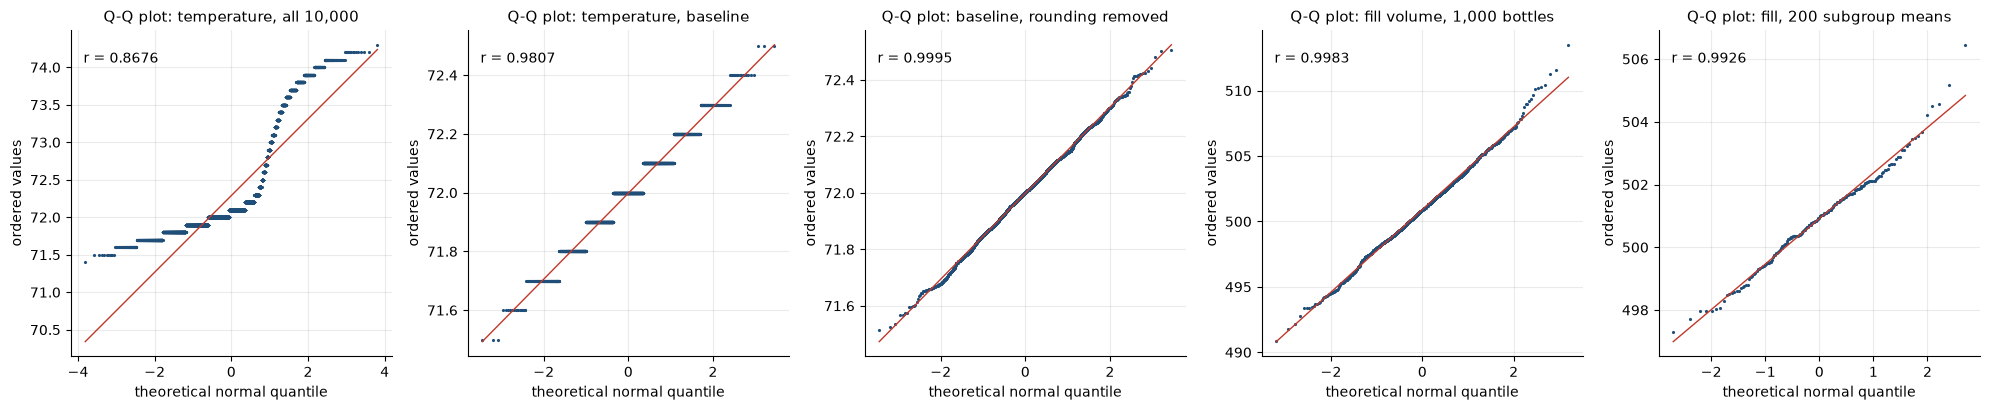

In [13]:
fig, ax = plt.subplots(1, 5, figsize=(20, 4.2))
for a, (name, x) in zip(ax, [("temperature, all 10,000", x_temp), ("temperature, baseline", x_base), ("baseline, rounding removed", x_base_jitter),
                             ("fill volume, 1,000 bottles", fill.Fill_Volume_ml.values), ("fill, 200 subgroup means", sub.xbar.values)]):
    (osm, osr), (sl, ic, rr) = stats.probplot(x, dist="norm")
    a.plot(osm, osr, ".", ms=2.5, color=COL["blue"]); a.plot(osm, sl * osm + ic, color=COL["red"], lw=1)
    a.set(title=f"Q-Q plot: {name}", xlabel="theoretical normal quantile", ylabel="ordered values"); a.text(0.04, 0.9, f"r = {rr:.4f}", transform=a.transAxes)
plt.tight_layout(); plt.show()

**What the tests say.**

* **Temperature, all readings:** strongly non-normal on every test (Shapiro p effectively 0, Anderson-Darling statistic 1,019 against a 1% critical value of about 1.03). The Q-Q plot bends away at both ends. This is the step and the drift, not a property of the noise.
* **Temperature, baseline window:** Shapiro-Wilk rejects normality (W = 0.962, p near 0) and Anderson-Darling agrees (46.5), **yet the shape is normal**: skewness -0.03 and excess kurtosis 0.03 are essentially zero and the D'Agostino test, which looks only at shape, does not reject. The Q-Q plot is a straight line with a staircase pattern. The cause is the one-decimal rounding: with a spread of 0.15 C the data take only about a dozen distinct values, and with 2,500 readings the tests detect the steps. Adding a small random amount (+/- 0.05 C) to undo the rounding gives Shapiro p = 0.11 and an Anderson-Darling statistic of 0.72 (below the critical value): normal.
* **Fill volume:** bottles and subgroup means are close to normal. Shapiro p = 0.053 for bottles and 0.064 for subgroup means (borderline, not rejected at 5%), Anderson-Darling 0.51 against a critical value of 1.03, and the D'Agostino p of 0.023 reflects the mild heavy upper tail seen in the histogram. The Q-Q plot is straight in the middle and lifts slightly at the top end.

The lesson is that a failed normality test is a prompt to look at the Q-Q plot, not a verdict.

baseline window: share of readings beyond +/-3 sigma = 0.240%  (normal theory: 0.270%)
3-sigma limits 71.559 to 72.437 C | 0.135/99.865 percentile limits 71.60 to 72.40 C
the same limits applied to ALL 10,000 readings flag 21.6% of readings: that is the step and the drift, not normality


,raw,Box-Cox,Yeo-Johnson
skewness,1.6152,0.1468,0.1593
excess kurtosis,1.4852,-0.0247,-0.3674
"Shapiro W (5,000 sample)",0.7527,0.9482,0.9541


Box-Cox lambda = -2.33; Yeo-Johnson lambda = -0.53


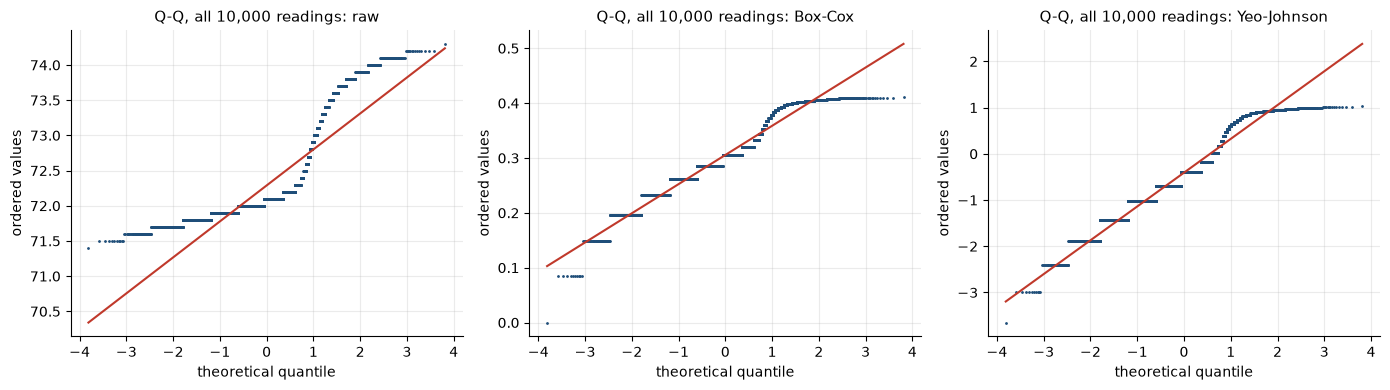

In [14]:
# What does the rounding (and the events) do to 3-sigma limits?  Quantify the false-alarm rate rather than assuming 0.27%.
sig_mr = np.abs(np.diff(x_base)).mean() / D2_IMR
z_base = (x_base - x_base.mean()) / sig_mr
obs_fa = np.mean(np.abs(z_base) > 3); exp_fa = 2 * stats.norm.sf(3)
pct_lo, pct_hi = np.percentile(x_base, [0.135, 99.865])
zq = lambda x: (x - x_base.mean()) / sig_mr
print(f"baseline window: share of readings beyond +/-3 sigma = {obs_fa * 100:.3f}%  (normal theory: {exp_fa * 100:.3f}%)")
print(f"3-sigma limits {x_base.mean() - 3 * sig_mr:.3f} to {x_base.mean() + 3 * sig_mr:.3f} C | 0.135/99.865 percentile limits {pct_lo:.2f} to {pct_hi:.2f} C")
fa_all = np.mean(np.abs(zq(x_temp)) > 3)
print(f"the same limits applied to ALL 10,000 readings flag {fa_all * 100:.1f}% of readings: that is the step and the drift, not normality")
# Transformations on the full series (the series that FAILS the tests): do they repair it?
xb_c, lam_bc = stats.boxcox(x_temp - x_temp.min() + 1); xy, lam_yj = stats.yeojohnson((x_temp - x_temp.mean()) / x_temp.std())   # Box-Cox needs positive values, so the series is shifted to start at 1; Yeo-Johnson is applied to the standardised series
tr = pd.DataFrame({"raw": x_temp, "Box-Cox": xb_c, "Yeo-Johnson": xy}).apply(lambda s: pd.Series({"skewness": stats.skew(s), "excess kurtosis": stats.kurtosis(s),
                   "Shapiro W (5,000 sample)": stats.shapiro(np.random.default_rng(SEED).choice(s.values, 5000, replace=False)).statistic}))
display(tr.round(4)); print(f"Box-Cox lambda = {lam_bc:.2f}; Yeo-Johnson lambda = {lam_yj:.2f}")
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (nm, y) in zip(ax, [("raw", x_temp), ("Box-Cox", xb_c), ("Yeo-Johnson", xy)]):
    (osm, osr), (sl, ic, rr) = stats.probplot(y, dist="norm"); a.plot(osm, osr, ".", ms=2, color=COL["blue"]); a.plot(osm, sl * osm + ic, color=COL["red"]); a.set(title=f"Q-Q, all 10,000 readings: {nm}", xlabel="theoretical quantile", ylabel="ordered values")
plt.tight_layout(); plt.show()
KEY.update(obs_fa=obs_fa * 100, exp_fa=exp_fa * 100, pct_lo=pct_lo, pct_hi=pct_hi, fa_all_full=fa_all * 100, lam_bc=lam_bc, sig_mr_base=sig_mr,
           bc_skew=tr.loc["skewness", "Box-Cox"], raw_skew=tr.loc["skewness", "raw"], bc_W=tr.loc["Shapiro W (5,000 sample)", "Box-Cox"], raw_W=tr.loc["Shapiro W (5,000 sample)", "raw"],
           lo3=x_base.mean() - 3 * sig_mr, hi3=x_base.mean() + 3 * sig_mr)

**What non-normality does to the control limits.** Three-sigma limits promise that about 0.27% of in-control points fall outside them. In the temperature baseline window, using limits worked out from the moving range, 0.24% of readings fall outside, essentially the promised rate. So the rounding makes the *tests* fail but does **not** distort the *limits*: ordinary individuals-chart limits are safe on the baseline stretch. Percentile limits (0.135th and 99.865th percentiles) are 71.60 to 72.40 C, against 3-sigma limits of 71.56 to 72.44 C, the same to within the 0.1 C resolution of the sensor.

Applied to all 10,000 readings, the same limits flag 21.6% of readings. That is not a false-alarm problem of the normal assumption; it is the process moving.

**Transformations.** A Box-Cox and a Yeo-Johnson transformation reduce the skewness of the whole series (from 1.62 to 0.15 with Box-Cox) and raise the Shapiro statistic (from 0.75 to 0.95) but the series still fails and, more importantly, a transformation would hide the events instead of explaining them. The sensible responses are: fit limits on a stable stretch (section 5), and use a method that looks for change over time (CUSUM, section 7). If a stable series were genuinely skewed, percentile limits or a Box-Cox transformation would be the first things to try; for the fill-volume data, which is close to normal, standard limits are appropriate.

<a id="s5"></a>
## 5. Control charts, built from the constants

No SPC library is used. The functions below calculate the limits directly from the formulae and constants:

* **Fill volume, subgrouped (n = 5): X-bar and R chart.** Centre line = grand mean of the subgroup means; X-bar limits = grand mean +/- A2 x R-bar (A2 = 0.577); R chart upper limit = D4 x R-bar (D4 = 2.114), lower limit = D3 x R-bar = 0. Within-subgroup sigma = R-bar / d2 (d2 = 2.326).
* **Temperature, one reading per second, no subgroups: Individuals and Moving Range (I-MR) chart.** Centre line = mean; limits = mean +/- 2.66 x MR-bar (which is 3 x MR-bar / 1.128); moving-range upper limit = 3.267 x MR-bar.
* **Zones and rules.** The charts shade the 1-, 2- and 3-sigma zones. Four rules flag signals: one point beyond 3 sigma; two of three beyond 2 sigma on one side; four of five beyond 1 sigma on one side; eight in a row on one side.

X-bar chart: grand mean 500.914, R-bar 7.257, A2 = 0.577, D4 = 2.114
  UCL = 500.914 + 0.577 x 7.257 = 505.101;  LCL = 496.726;  R chart UCL = 2.114 x 7.257 = 15.342
  signalled subgroups by rule: {'R1 beyond 3 sigma': [125, 128], 'R2 two of three beyond 2 sigma': [22], 'R3 four of five beyond 1 sigma': [24, 125], 'R4 eight in a row one side': []} | R chart above UCL: [48]


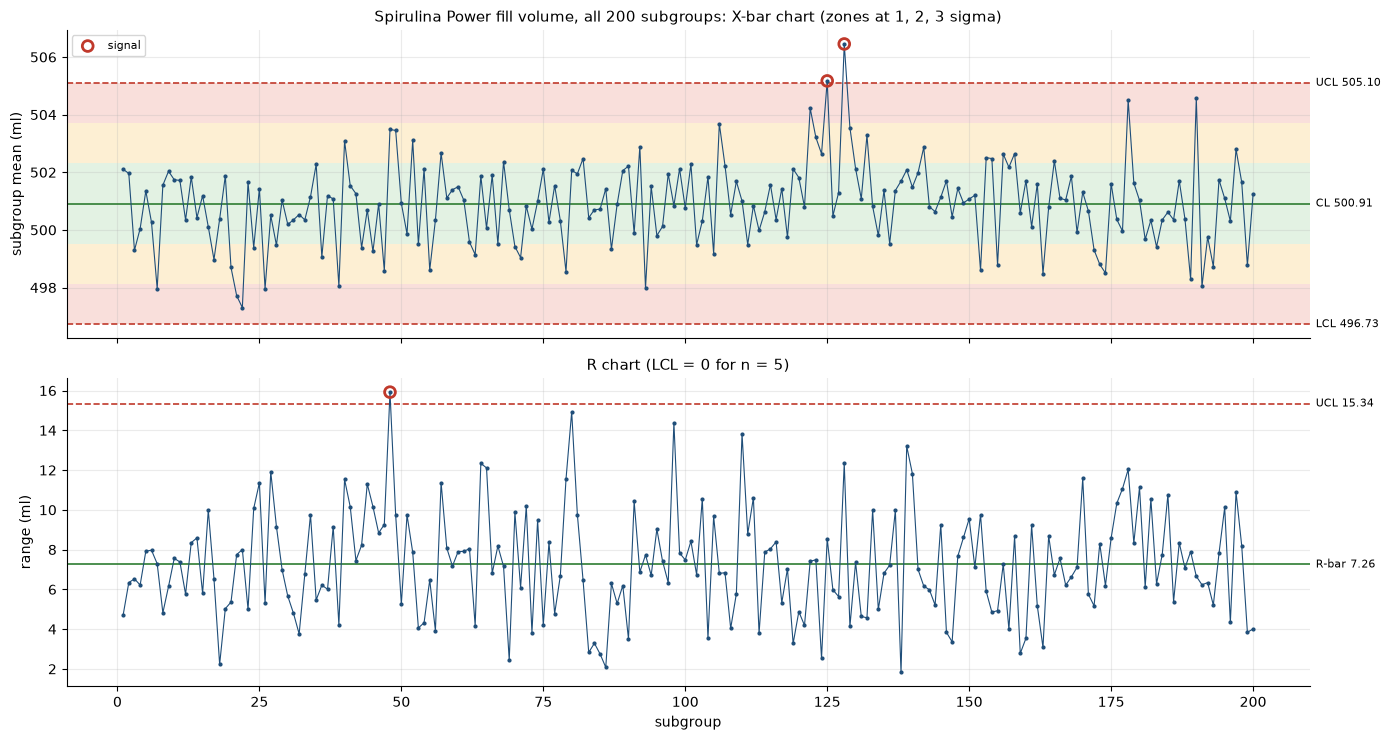

In [15]:
# ===== control-chart toolkit: limits from the constants, zones, run rules, plots =====
def xbar_r_limits(Xmat):
    """X-bar and R limits from an (k x n) array of subgroups: CL +/- A2*Rbar, D3*Rbar, D4*Rbar."""
    n = Xmat.shape[1]; A2, D3, D4, d2 = CONST[n]
    xb = Xmat.mean(axis=1); R = np.ptp(Xmat, axis=1); xbb, rbar = xb.mean(), R.mean()
    return dict(n=n, k=len(xb), xbb=xbb, rbar=rbar, A2=A2, D3=D3, D4=D4, d2=d2, ucl_x=xbb + A2 * rbar, lcl_x=xbb - A2 * rbar,
                ucl_r=D4 * rbar, lcl_r=D3 * rbar, sigma_w=rbar / d2, sigma_x=A2 * rbar / 3, xb=xb, R=R)

def imr_limits(x):
    """Individuals / moving-range limits: CL +/- 3*MRbar/d2 (= 2.66*MRbar), MR UCL = 3.267*MRbar."""
    x = np.asarray(x, float); mr = np.abs(np.diff(x)); cl, mrbar = x.mean(), mr.mean()
    sig = mrbar / D2_IMR
    return dict(k=len(x), cl=cl, mrbar=mrbar, sigma=sig, ucl=cl + E2_IMR * mrbar, lcl=cl - E2_IMR * mrbar, ucl_mr=D4_IMR * mrbar)

def run_rules(z):
    """Four Western Electric / Nelson tests on standardised points z. Returns {rule: boolean array}."""
    z = np.asarray(z, float); n = len(z)
    def k_of_m(thr, k, m):
        up = (z > thr).astype(int); dn = (z < -thr).astype(int)
        cu = np.convolve(up, np.ones(m, int))[:n]; cd = np.convolve(dn, np.ones(m, int))[:n]
        return ((cu >= k) & (z > thr)) | ((cd >= k) & (z < -thr))
    pos = (z > 0).astype(int); neg = (z < 0).astype(int)
    eight = (np.convolve(pos, np.ones(8, int))[:n] == 8) | (np.convolve(neg, np.ones(8, int))[:n] == 8)
    eight[:7] = False
    return {"R1 beyond 3 sigma": np.abs(z) > 3, "R2 two of three beyond 2 sigma": k_of_m(2, 2, 3), "R3 four of five beyond 1 sigma": k_of_m(1, 4, 5), "R4 eight in a row one side": eight}

def draw_zones(ax, cl, sigma, x0, x1):
    """Shade the 1-, 2- and 3-sigma zones and draw the limits."""
    for m, c in ((3, "#f8d7d3"), (2, "#fdebc8"), (1, "#dcefdc")):
        ax.axhspan(cl + (m - 1) * sigma, cl + m * sigma, color=c, alpha=0.8, lw=0); ax.axhspan(cl - m * sigma, cl - (m - 1) * sigma, color=c, alpha=0.8, lw=0)
    ax.axhline(cl, color=COL["green"], lw=1.2); ax.axhline(cl + 3 * sigma, color=COL["red"], ls="--", lw=1.2); ax.axhline(cl - 3 * sigma, color=COL["red"], ls="--", lw=1.2)

def plot_xbar_r(lim, flags_x, flags_r, title, fig_w=14):
    fig, ax = plt.subplots(2, 1, figsize=(fig_w, 7.5), sharex=True); i = np.arange(1, lim["k"] + 1)
    a = ax[0]; draw_zones(a, lim["xbb"], lim["sigma_x"], 1, lim["k"]); a.plot(i, lim["xb"], ".-", color=COL["blue"], lw=0.8, ms=4)
    a.scatter(i[flags_x], lim["xb"][flags_x], s=60, facecolors="none", edgecolors=COL["red"], lw=2, label="signal", zorder=5)
    a.text(1.005, lim["ucl_x"], f"UCL {lim['ucl_x']:.2f}", transform=a.get_yaxis_transform(), va="center", fontsize=8); a.text(1.005, lim["lcl_x"], f"LCL {lim['lcl_x']:.2f}", transform=a.get_yaxis_transform(), va="center", fontsize=8)
    a.text(1.005, lim["xbb"], f"CL {lim['xbb']:.2f}", transform=a.get_yaxis_transform(), va="center", fontsize=8)
    a.set(title=title + ": X-bar chart (zones at 1, 2, 3 sigma)", ylabel="subgroup mean (ml)"); a.legend(loc="upper left")
    a = ax[1]; a.axhline(lim["rbar"], color=COL["green"], lw=1.2); a.axhline(lim["ucl_r"], color=COL["red"], ls="--", lw=1.2); a.plot(i, lim["R"], ".-", color=COL["blue"], lw=0.8, ms=4)
    a.scatter(i[flags_r], lim["R"][flags_r], s=60, facecolors="none", edgecolors=COL["red"], lw=2, zorder=5)
    a.text(1.005, lim["ucl_r"], f"UCL {lim['ucl_r']:.2f}", transform=a.get_yaxis_transform(), va="center", fontsize=8); a.text(1.005, lim["rbar"], f"R-bar {lim['rbar']:.2f}", transform=a.get_yaxis_transform(), va="center", fontsize=8)
    a.set(title="R chart (LCL = 0 for n = 5)", xlabel="subgroup", ylabel="range (ml)"); plt.tight_layout(); plt.show()

fx = xbar_r_limits(X)
z_x = (fx["xb"] - fx["xbb"]) / fx["sigma_x"]
rules_x = run_rules(z_x); sig_x = np.zeros(fx["k"], bool)
for v in rules_x.values(): sig_x |= v
sig_r = fx["R"] > fx["ucl_r"]
print(f"X-bar chart: grand mean {fx['xbb']:.3f}, R-bar {fx['rbar']:.3f}, A2 = {fx['A2']}, D4 = {fx['D4']}")
print(f"  UCL = {fx['xbb']:.3f} + {fx['A2']} x {fx['rbar']:.3f} = {fx['ucl_x']:.3f};  LCL = {fx['lcl_x']:.3f};  R chart UCL = {fx['D4']} x {fx['rbar']:.3f} = {fx['ucl_r']:.3f}")
print("  signalled subgroups by rule:", {k: (np.where(v)[0] + 1).tolist() for k, v in rules_x.items()}, "| R chart above UCL:", (np.where(sig_r)[0] + 1).tolist())
plot_xbar_r(fx, rules_x["R1 beyond 3 sigma"], sig_r, "Spirulina Power fill volume, all 200 subgroups")
KEY.update(fx_xbb=fx["xbb"], fx_rbar=fx["rbar"], fx_ucl=fx["ucl_x"], fx_lcl=fx["lcl_x"], fx_ucl_r=fx["ucl_r"], fx_sig_w=fx["sigma_w"], fx_sig_x=fx["sigma_x"],
           fx_n_r1=int(rules_x["R1 beyond 3 sigma"].sum()), fx_n_any=int(sig_x.sum()), fx_n_rsig=int(sig_r.sum()),
           fx_r1_list=", ".join(str(v) for v in (np.where(rules_x["R1 beyond 3 sigma"])[0] + 1)), fx_r_list=", ".join(str(v) for v in (np.where(sig_r)[0] + 1)),
           fx_rule_counts=", ".join(f"{k.split()[0]}: {int(v.sum())}" for k, v in rules_x.items()))

In [16]:
# Phase I: remove the signalled subgroups (assignable causes assumed found) and recompute once; compare the limits.
keep_sub = ~(rules_x["R1 beyond 3 sigma"] | sig_r)
fx2 = xbar_r_limits(X[keep_sub])
z2 = (fx["xb"] - fx2["xbb"]) / fx2["sigma_x"]; sig2 = np.abs(z2) > 3; sig2_r = fx["R"] > fx2["ucl_r"]
cmp_fill = pd.DataFrame({"all 200 subgroups": [fx["k"], fx["xbb"], fx["rbar"], fx["lcl_x"], fx["ucl_x"], fx["ucl_r"], fx["sigma_w"], int(rules_x["R1 beyond 3 sigma"].sum()), int(sig_r.sum())],
                         "after removing signalled subgroups": [fx2["k"], fx2["xbb"], fx2["rbar"], fx2["lcl_x"], fx2["ucl_x"], fx2["ucl_r"], fx2["sigma_w"], int(sig2.sum()), int(sig2_r.sum())]},
                        index=["subgroups used", "grand mean (ml)", "R-bar (ml)", "X-bar LCL", "X-bar UCL", "R UCL", "sigma within (ml)", "X-bar points beyond 3 sigma (all 200 plotted)", "R points above UCL (all 200 plotted)"])
display(cmp_fill.round(3))
KEY.update(fx2_k=fx2["k"], fx2_ucl=fx2["ucl_x"], fx2_lcl=fx2["lcl_x"], fx2_rbar=fx2["rbar"], fx2_ucl_r=fx2["ucl_r"], fx2_n_x=int(sig2.sum()), fx2_n_r=int(sig2_r.sum()))

,all 200 subgroups,after removing signalled subgroups
subgroups used,200.000,197.000
grand mean (ml),500.914,500.851
R-bar (ml),7.257,7.181
X-bar LCL,496.726,496.708
X-bar UCL,505.101,504.994
R UCL,15.342,15.180
sigma within (ml),3.120,3.087
X-bar points beyond 3 sigma (all 200 plotted),2.000,2.000
R points above UCL (all 200 plotted),1.000,1.000


**Fill volume: X-bar and R chart.** The centre line is 500.91 ml and R-bar is 7.26 ml. By hand: UCL = 500.914 + 0.577 x 7.257 = 505.10 ml and LCL = 496.73 ml; the R chart limit is 2.114 x 7.257 = 15.34 ml. (The within-subgroup sigma, R-bar / 2.326, is 3.12 ml.)

The process is mostly in control, with a few isolated signals: subgroups **125, 128** are beyond the 3-sigma limit on the X-bar chart (2 points), the R chart has one range above its limit (subgroup **48**), and the two- and four-point rules add signals at subgroups 22, 24 and 125 (counts by rule: R1: 2, R2: 1, R3: 2, R4: 0). There is no sustained run or trend. The two beyond-limit subgroups, 125 and 128, both fall in operator MB's run (the operator whose subgroup means are higher, section 3) and 128 contains the highest bottle in the file (513.5 ml). These look like **occasional over-fills** (for example, a filling valve or head that sometimes dispenses extra), not a drifting process.

**Phase I limits.** Removing the three signalled subgroups and recalculating changes little: the X-bar limits move from 496.73 to 505.10 ml to 496.71 to 504.99 ml and the R limit from 15.34 to 15.18 ml. The same two subgroups still sit outside. This means the original limits are not distorted by the signals, so the all-subgroup limits are kept and used for capability in section 6.

In [17]:
# ===== Temperature I-MR: two fits, one figure =====
lim_b = imr_limits(x_base)          # fitted on the settled opening stretch only
lim_a = imr_limits(x_temp)          # fitted on all 10,000 readings

def flags_for(x, lim):
    z = (x - lim["cl"]) / lim["sigma"]; r = run_rules(z); mr = np.r_[np.nan, np.abs(np.diff(x))]
    return z, r, mr > lim["ucl_mr"]

res = {}
for name, lim in (("baseline fit (readings 1-2500)", lim_b), ("all-readings fit (1-10,000)", lim_a)):
    z, r, mrf = flags_for(x_temp, lim)
    i_out = np.abs(z) > 3
    first_i = int(np.argmax(i_out)) + 1 if i_out.any() else None
    drift_zone = np.arange(1, len(x_temp) + 1) >= tb
    ev_zone = (np.arange(1, len(x_temp) + 1) >= ev_start) & (np.arange(1, len(x_temp) + 1) <= ev_end)
    quiet = ~(drift_zone | ev_zone)
    res[name] = {"centre line (C)": lim["cl"], "sigma (MR-bar/1.128)": lim["sigma"], "LCL (C)": lim["lcl"], "UCL (C)": lim["ucl"], "MR UCL (C)": lim["ucl_mr"],
                 "I points beyond 3 sigma": int(i_out.sum()), "  of which in the quiet stretches": int((i_out & quiet).sum()), "  of which in the step": int((i_out & ev_zone).sum()),
                 "  of which in the drift period": int((i_out & drift_zone).sum()), "first I signal at reading": first_i,
                 "MR points above UCL": int(np.nansum(mrf)), "R4 (8 in a row one side) points": int(r["R4 eight in a row one side"].sum()),
                 "R4 points in the quiet stretches": int((r["R4 eight in a row one side"] & quiet).sum()),
                 "share of the drift period flagged (R1)": float((i_out & drift_zone).sum() / drift_zone.sum()), "share of the quiet stretches flagged (R1)": float((i_out & quiet).sum() / quiet.sum())}
cmp_t = pd.DataFrame(res); display(cmp_t.round(4))
print(f"\nby hand, baseline fit: UCL = CL + 2.66 x MR-bar = {lim_b['cl']:.4f} + 2.66 x {lim_b['mrbar']:.4f} = {lim_b['cl'] + 2.66 * lim_b['mrbar']:.4f}")
KEY.update(tb_cl=lim_b["cl"], tb_sigma=lim_b["sigma"], tb_ucl=lim_b["ucl"], tb_lcl=lim_b["lcl"], tb_mrbar=lim_b["mrbar"], tb_ucl_mr=lim_b["ucl_mr"],
           ta_cl=lim_a["cl"], ta_sigma=lim_a["sigma"], ta_ucl=lim_a["ucl"], ta_lcl=lim_a["lcl"], ta_mrbar=lim_a["mrbar"], ta_ucl_mr=lim_a["ucl_mr"])
for key, nm in (("tb", "baseline fit (readings 1-2500)"), ("ta", "all-readings fit (1-10,000)")):
    c = cmp_t[nm]
    KEY.update({key + "_n_i": int(c["I points beyond 3 sigma"]), key + "_n_quiet": int(c["  of which in the quiet stretches"]), key + "_n_step": int(c["  of which in the step"]),
                key + "_n_drift": int(c["  of which in the drift period"]), key + "_first": c["first I signal at reading"], key + "_n_mr": int(c["MR points above UCL"]),
                key + "_r4": int(c["R4 (8 in a row one side) points"]), key + "_r4_quiet": int(c["R4 points in the quiet stretches"]),
                key + "_drift_share": float(c["share of the drift period flagged (R1)"]) * 100, key + "_quiet_share": float(c["share of the quiet stretches flagged (R1)"]) * 100})

,baseline fit (readings 1-2500),"all-readings fit (1-10,000)"
centre line (C),71.9980,72.2888
sigma (MR-bar/1.128),0.1463,0.1484
LCL (C),71.5592,71.8434
UCL (C),72.4369,72.7342
MR UCL (C),0.5390,0.5470
I points beyond 3 sigma,2165.0000,2946.0000
of which in the quiet stretches,34.0000,1153.0000
of which in the step,276.0000,274.0000
of which in the drift period,1855.0000,1519.0000
first I signal at reading,325.0000,10.0000



by hand, baseline fit: UCL = CL + 2.66 x MR-bar = 71.9980 + 2.66 x 0.1650 = 72.4369


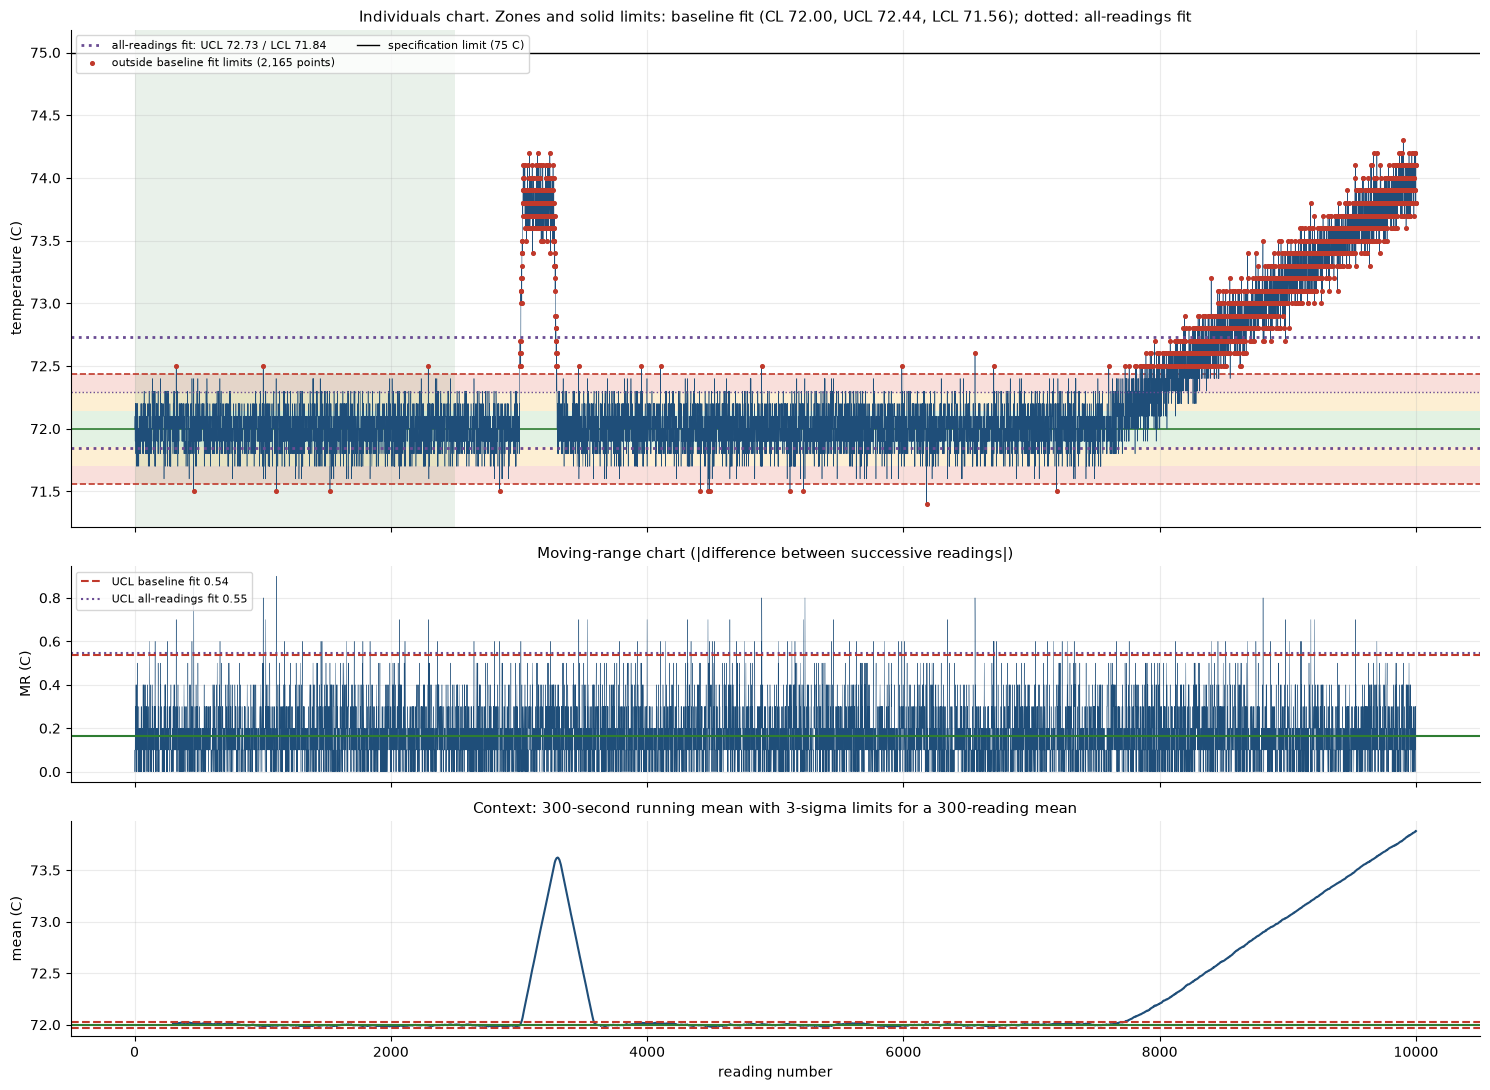

In [18]:
def plot_imr_two_fits(x, lim_keep, lim_other, keep_label, other_label):
    t = np.arange(1, len(x) + 1); z, _, mrf = flags_for(x, lim_keep); z2, _, mrf2 = flags_for(x, lim_other)
    fig, ax = plt.subplots(3, 1, figsize=(15, 11), sharex=True, gridspec_kw={"height_ratios": [3, 1.3, 1.3]})
    a = ax[0]; draw_zones(a, lim_keep["cl"], lim_keep["sigma"], 1, len(x)); a.plot(t, x, lw=0.4, color=COL["blue"])
    a.axhline(lim_other["ucl"], color=COL["purple"], ls=":", lw=2, label=f"{other_label}: UCL {lim_other['ucl']:.2f} / LCL {lim_other['lcl']:.2f}"); a.axhline(lim_other["lcl"], color=COL["purple"], ls=":", lw=2)
    a.axhline(lim_other["cl"], color=COL["purple"], ls=":", lw=1)
    a.scatter(t[np.abs(z) > 3], x[np.abs(z) > 3], s=7, color=COL["red"], label=f"outside {keep_label} limits ({int((np.abs(z) > 3).sum()):,} points)", zorder=5)
    a.axvspan(*BASELINE, color=COL["green"], alpha=0.10, lw=0); a.axhline(T_USL, color="k", lw=1, label="specification limit (75 C)")
    a.set(title=f"Individuals chart. Zones and solid limits: {keep_label} (CL {lim_keep['cl']:.2f}, UCL {lim_keep['ucl']:.2f}, LCL {lim_keep['lcl']:.2f}); dotted: {other_label}", ylabel="temperature (C)"); a.legend(loc="upper left", ncol=2)
    mr = np.abs(np.diff(x)); a = ax[1]; a.plot(t[1:], mr, lw=0.3, color=COL["blue"]); a.axhline(lim_keep["mrbar"], color=COL["green"]); a.axhline(lim_keep["ucl_mr"], color=COL["red"], ls="--", label=f"UCL {keep_label} {lim_keep['ucl_mr']:.2f}")
    a.axhline(lim_other["ucl_mr"], color=COL["purple"], ls=":", label=f"UCL {other_label} {lim_other['ucl_mr']:.2f}"); a.set(title="Moving-range chart (|difference between successive readings|)", ylabel="MR (C)"); a.legend(loc="upper left")
    a = ax[2]; rl = pd.Series(x).rolling(300).mean(); a.plot(t, rl, color=COL["blue"]); a.axhline(lim_keep["cl"], color=COL["green"]); a.axhline(lim_keep["cl"] + 3 * lim_keep["sigma"] / np.sqrt(300), color=COL["red"], ls="--"); a.axhline(lim_keep["cl"] - 3 * lim_keep["sigma"] / np.sqrt(300), color=COL["red"], ls="--")
    a.set(title="Context: 300-second running mean with 3-sigma limits for a 300-reading mean", xlabel="reading number", ylabel="mean (C)")
    plt.tight_layout(); plt.show()

plot_imr_two_fits(x_temp, lim_b, lim_a, "baseline fit", "all-readings fit")

**Temperature: I-MR chart, two sets of limits.** The solid zones and limits come from the **baseline window** (readings 1 to 2,500); the dotted lines come from **all 10,000 readings**. Both are applied to the whole run.

| | baseline fit (1 to 2,500) | all-readings fit |
|---|---|---|
| centre line | 71.998 C | 72.289 C |
| limits (LCL to UCL) | 71.56 to 72.44 C | 71.84 to 72.73 C |
| sigma (MR-bar / 1.128) | 0.1463 C | 0.1484 C |
| readings beyond 3 sigma | 2,165 | 2,946 |
| ... in the quiet stretches (before the step, between, and before the drift) | 34 (0.46% of them) | 1,153 (15.7% of them) |
| ... in the drift period | 1,855 (77% of it) | 1,519 (63% of it) |
| first reading flagged | 325.0 | 10.0 |

By hand, the baseline UCL is 71.998 + 2.66 x 0.165 = 72.44 C. The two moving-range limits are almost the same (0.54 and 0.55 C) because the moving range measures second-to-second noise, which the events barely change.

**What this shows.** Fitting on all readings drags the centre line from 72.00 to 72.29 C. The limits widen at the top, so part of the drift now sits inside them (the share of the drift period flagged falls from 77% to 63%), and the settled opening stretch moves off the bottom of the new limits: 16% of the quiet readings are now flagged, starting at reading 10.0, against 0.46% with the baseline fit. The all-readings chart therefore blames the quiet stretch and excuses part of the fault. The step (about 276 readings) is flagged in full by both.

The chart also marks every point of the drift beyond the upper limit, yet no reading is near the 75 C specification limit. That is the point of the control chart: it reacts to a change in the *process* long before the *specification* is at risk.

### 5.4 Which limits I keep (DRAFT: rewrite in your own words)

**I keep the baseline fit (readings 1 to 2,500; centre line 72.00 C; limits 71.56 to 72.44 C).** Control limits are meant to describe how the process behaves when it is holding steady, so they have to be fitted on a stretch where nothing was moving. Readings 1 to 2,500 (the first 41 minutes) are steady on every test I ran: no trend, no autocorrelation, and a spread equal to the rest of the quiet stretches. They stop well before the first event at reading about 3014. Fitting on all 10,000 readings would let the step and the drift pull the centre line up to 72.29 C and wrongly flag the quiet opening of the run (16% of quiet readings) while excusing part of the drift.

Two caveats I would tell the quality manager: (1) the baseline is only 2,500 readings from one 41-minute stretch, so the limits should be refitted after maintenance, once there is a longer clean stretch; (2) even on the baseline fit, a few quiet readings (34, 0.46%) fall outside, which is about what 3-sigma limits allow.

In [19]:
# Sensitivity of the conclusions to limit width and to subgroup size
rows = []
for kk in (2.0, 2.5, 3.0, 3.5, 4.0):
    zb = np.abs(x_temp - lim_b["cl"]) / lim_b["sigma"]
    rows.append({"limit width (sigma)": kk, "false alarms in baseline window": int((zb[b0:b1] > kk).sum()), "share of baseline flagged %": 100 * (zb[b0:b1] > kk).mean(),
                 "step readings flagged %": 100 * (zb[ev_start - 1:ev_end] > kk).mean(), "drift-period readings flagged %": 100 * (zb[tb:] > kk).mean()})
sens_t = pd.DataFrame(rows); display(sens_t.round(2))
rows = []
for n_try in (2, 4, 5, 8, 10):
    Xn = fill.Fill_Volume_ml.to_numpy().reshape(-1, n_try); ln = xbar_r_limits(Xn); zn = (ln["xb"] - ln["xbb"]) / ln["sigma_x"]
    rows.append({"subgroup size n": n_try, "subgroups": ln["k"], "X-bar UCL": ln["ucl_x"], "X-bar LCL": ln["lcl_x"], "R-bar": ln["rbar"], "sigma within": ln["sigma_w"],
                 "X-bar points beyond 3 sigma": int((np.abs(zn) > 3).sum()), "R points above UCL": int((ln["R"] > ln["ucl_r"]).sum())})
sens_f = pd.DataFrame(rows); display(sens_f.round(3))
KEY.update(sens_pct_2=float(sens_t.iloc[0, 2]), sens_r_n2=int(sens_f.iloc[0, 7]), sens_r_n5=int(sens_f.iloc[2, 7]), sens_fa_2=int(sens_t.iloc[0, 1]), sens_fa_3=int(sens_t.iloc[2, 1]), sens_drift_2=float(sens_t.iloc[0, 4]), sens_drift_3=float(sens_t.iloc[2, 4]), sens_drift_4=float(sens_t.iloc[4, 4]),
           sens_n2_sw=float(sens_f.iloc[0, 5]), sens_n10_sw=float(sens_f.iloc[4, 5]))

,limit width (sigma),false alarms in baseline window,share of baseline flagged %,step readings flagged %,drift-period readings flagged %
0,2.0,237,9.48,100.00,87.38
1,2.5,39,1.56,100.00,82.83
2,3.0,6,0.24,100.00,77.29
3,3.5,0,0.00,99.64,72.46
4,4.0,0,0.00,99.64,72.46


,subgroup size n,subgroups,X-bar UCL,X-bar LCL,R-bar,sigma within,X-bar points beyond 3 sigma,R points above UCL
0,2,500,507.955,493.873,3.745,3.320,2,6
1,4,250,505.719,496.109,6.591,3.201,1,1
2,5,200,505.101,496.726,7.257,3.120,2,1
3,8,125,504.255,497.572,8.958,3.147,1,1
4,10,100,503.915,497.913,9.744,3.166,1,1


**Sensitivity.** *Limit width (temperature):* at 2-sigma limits the baseline window itself raises 237 false alarms (9.5% of readings) and the drift is flagged 87% of the time; at 3 sigma there are 6 baseline alarms and the drift is flagged 77%; at 3.5 or 4 sigma the baseline is silent. Since the detectors in section 7 do the early-warning job, the chart limits stay at 3 sigma. *Subgroup size (fill volume):* regrouping the 1,000 bottles into subgroups of 2, 4, 5, 8 or 10 leaves the estimate of within sigma almost unchanged (3.32 to 3.17 ml for n = 2 to 10) and the same few subgroups keep signalling; very small subgroups (n = 2) raise more false range alarms (6 against 1). Subgroups of five are a good compromise.

<a id="s6"></a>
## 6. Capability of the fill process

Capability compares the process with the **specification** (490 to 510 ml, target 500 ml). Four indices:

* **Cp** = (USL - LSL) / (6 x sigma within) and **Cpk** = the smaller of (USL - mean) and (mean - LSL), divided by (3 x sigma within). These use the within-subgroup sigma (R-bar / d2), the short-term variation: *what the filler can do when it is behaving.*
* **Pp** and **Ppk**: the same formulas with the overall sample standard deviation, which includes any movement between subgroups: *what the customer actually received.*

95% intervals come from the standard chi-square formula for Cp and Pp, the Bissell normal approximation for Cpk and Ppk, and a **bootstrap** (resampling whole subgroups, 2,000 times) as a cross-check. Expected parts per million (PPM) outside the limits use the normal curve; the observed count comes straight from the data.

In [20]:
def capability(Xmat, lsl, usl, n_boot=2000, seed=SEED):
    """Cp/Cpk (within sigma = R-bar/d2) and Pp/Ppk (overall sample sigma), with 95% intervals.
    Cp/Pp: chi-square interval. Cpk/Ppk: large-sample normal approximation (Bissell). Bootstrap: resample whole subgroups."""
    lim = xbar_r_limits(Xmat); x = Xmat.ravel(); N = len(x); mu = x.mean(); sw, so = lim["sigma_w"], x.std(ddof=1)
    def idx(mu_, s):
        return (usl - lsl) / (6 * s), min(usl - mu_, mu_ - lsl) / (3 * s)
    cp, cpk = idx(mu, sw); pp, ppk = idx(mu, so)
    ci_c = lambda v: (v * np.sqrt(stats.chi2.ppf(0.025, N - 1) / (N - 1)), v * np.sqrt(stats.chi2.ppf(0.975, N - 1) / (N - 1)))
    ci_k = lambda v: (v - 1.96 * np.sqrt(1 / (9 * N) + v ** 2 / (2 * (N - 1))), v + 1.96 * np.sqrt(1 / (9 * N) + v ** 2 / (2 * (N - 1))))
    r = np.random.default_rng(seed); boots = []
    for _ in range(n_boot):
        Xb = Xmat[r.integers(0, len(Xmat), len(Xmat))]; lb = xbar_r_limits(Xb); xb_ = Xb.ravel(); mb = xb_.mean()
        boots.append((idx(mb, lb["sigma_w"])[1], idx(mb, xb_.std(ddof=1))[1]))
    boots = np.array(boots)
    ppm = lambda s: (1e6 * stats.norm.cdf(lsl, mu, s), 1e6 * stats.norm.sf(usl, mu, s))
    return dict(mu=mu, sigma_w=sw, sigma_o=so, cp=cp, cpk=cpk, pp=pp, ppk=ppk, cp_ci=ci_c(cp), pp_ci=ci_c(pp), cpk_ci=ci_k(cpk), ppk_ci=ci_k(ppk),
                cpk_boot=tuple(np.percentile(boots[:, 0], [2.5, 97.5])), ppk_boot=tuple(np.percentile(boots[:, 1], [2.5, 97.5])),
                ppm_w=ppm(sw), ppm_o=ppm(so), obs_lo=int((x < lsl).sum()), obs_hi=int((x > usl).sum()), N=N)

cap = capability(X, F_LSL, F_USL)
cap_tab = pd.DataFrame({"estimate": [cap["cp"], cap["cpk"], cap["pp"], cap["ppk"]],
                        "95% interval (formula)": [f"{cap[k + '_ci'][0]:.2f} to {cap[k + '_ci'][1]:.2f}" for k in ("cp", "cpk", "pp", "ppk")],
                        "95% interval (bootstrap)": ["", f"{cap['cpk_boot'][0]:.2f} to {cap['cpk_boot'][1]:.2f}", "", f"{cap['ppk_boot'][0]:.2f} to {cap['ppk_boot'][1]:.2f}"],
                        "sigma used (ml)": [cap["sigma_w"], cap["sigma_w"], cap["sigma_o"], cap["sigma_o"]]}, index=["Cp", "Cpk", "Pp", "Ppk"])
display(cap_tab.round(3))
ppm_tab = pd.DataFrame({"expected below 490 ml (PPM)": [cap["ppm_w"][0], cap["ppm_o"][0]], "expected above 510 ml (PPM)": [cap["ppm_w"][1], cap["ppm_o"][1]]}, index=["within sigma", "overall sigma"])
ppm_tab["expected total (PPM)"] = ppm_tab.sum(axis=1); display(ppm_tab.round(0))
print(f"observed: {cap['obs_lo']} bottles below {F_LSL} ml and {cap['obs_hi']} above {F_USL} ml out of {cap['N']:,} = {(cap['obs_lo'] + cap['obs_hi']) / cap['N'] * 1e6:,.0f} PPM")
KEY.update({f"cap_{k}": cap[k] for k in ("mu", "sigma_w", "sigma_o", "cp", "cpk", "pp", "ppk", "obs_lo", "obs_hi", "N")},
           cap_cpk_lo=cap["cpk_ci"][0], cap_cpk_hi=cap["cpk_ci"][1], cap_ppk_lo=cap["ppk_ci"][0], cap_ppk_hi=cap["ppk_ci"][1], cap_cp_lo=cap["cp_ci"][0], cap_cp_hi=cap["cp_ci"][1],
           cap_pp_lo=cap["pp_ci"][0], cap_pp_hi=cap["pp_ci"][1], cap_cpk_bl=cap["cpk_boot"][0], cap_cpk_bh=cap["cpk_boot"][1], cap_ppk_bl=cap["ppk_boot"][0], cap_ppk_bh=cap["ppk_boot"][1],
           ppm_w_lo=cap["ppm_w"][0], ppm_w_hi=cap["ppm_w"][1], ppm_o_lo=cap["ppm_o"][0], ppm_o_hi=cap["ppm_o"][1], ppm_w_tot=sum(cap["ppm_w"]), ppm_o_tot=sum(cap["ppm_o"]),
           obs_ppm=(cap["obs_lo"] + cap["obs_hi"]) / cap["N"] * 1e6, exp_hi_count=cap["ppm_w"][1] / 1000, hi_ratio=cap["obs_hi"] / (cap["ppm_w"][1] / 1000), exp_lo_count=cap["ppm_w"][0] / 1000)

,estimate,95% interval (formula),95% interval (bootstrap),sigma used (ml)
Cp,1.068,1.02 to 1.12,,3.120
Cpk,0.971,0.92 to 1.02,0.92 to 1.03,3.120
Pp,1.056,1.01 to 1.10,,3.157
Ppk,0.959,0.91 to 1.01,0.91 to 1.02,3.157


,expected below 490 ml (PPM),expected above 510 ml (PPM),expected total (PPM)
within sigma,234.0,1794.0,2029.0
overall sigma,273.0,2002.0,2275.0


observed: 0 bottles below 490.0 ml and 7 above 510.0 ml out of 1,000 = 7,000 PPM


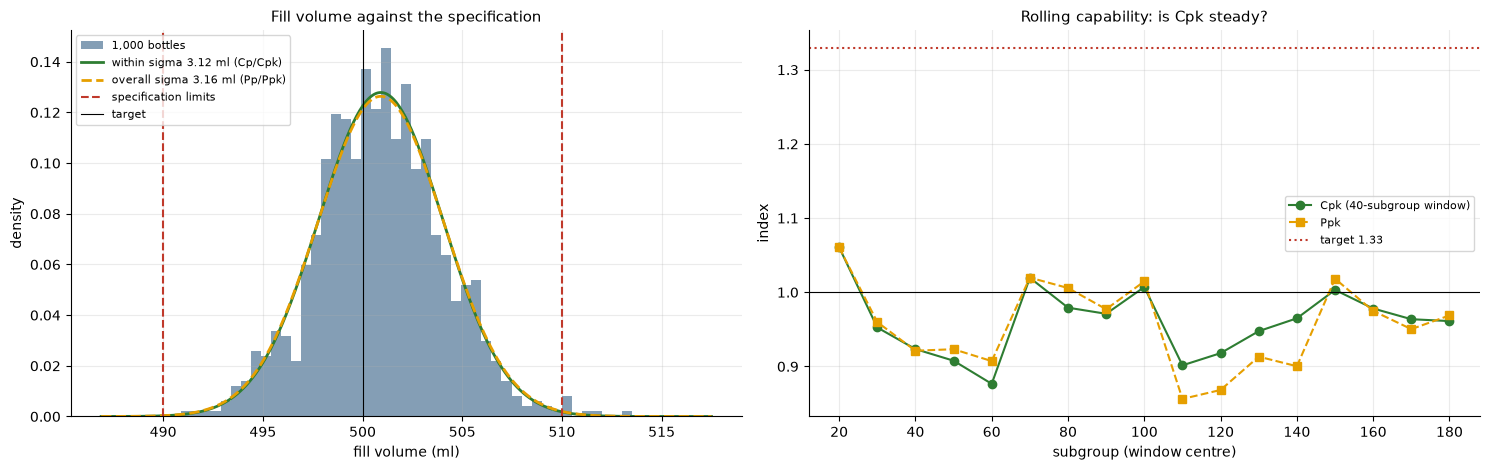

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
a = ax[0]; v = fill.Fill_Volume_ml.values; g = np.linspace(v.min() - 4, v.max() + 4, 400)
a.hist(v, bins=45, density=True, color=COL["blue"], alpha=0.55, label="1,000 bottles")
a.plot(g, stats.norm.pdf(g, cap["mu"], cap["sigma_w"]), color=COL["green"], lw=2, label=f"within sigma {cap['sigma_w']:.2f} ml (Cp/Cpk)")
a.plot(g, stats.norm.pdf(g, cap["mu"], cap["sigma_o"]), color=COL["amber"], lw=2, ls="--", label=f"overall sigma {cap['sigma_o']:.2f} ml (Pp/Ppk)")
a.axvline(F_LSL, color=COL["red"], ls="--"); a.axvline(F_USL, color=COL["red"], ls="--", label="specification limits"); a.axvline(F_TGT, color="k", lw=0.8, label="target")
a.set(title="Fill volume against the specification", xlabel="fill volume (ml)", ylabel="density"); a.legend(loc="upper left")
a = ax[1]; win, step = 40, 10; xs, cpk_r, ppk_r = [], [], []
for s0 in range(0, 200 - win + 1, step):
    c = capability(X[s0:s0 + win], F_LSL, F_USL, n_boot=1); xs.append(s0 + win / 2); cpk_r.append(c["cpk"]); ppk_r.append(c["ppk"])
a.plot(xs, cpk_r, "o-", color=COL["green"], label="Cpk (40-subgroup window)"); a.plot(xs, ppk_r, "s--", color=COL["amber"], label="Ppk"); a.axhline(TARGET_CPK, color=COL["red"], ls=":", label=f"target {TARGET_CPK}"); a.axhline(1.0, color="k", lw=0.8)
a.set(title="Rolling capability: is Cpk steady?", xlabel="subgroup (window centre)", ylabel="index"); a.legend(); plt.tight_layout(); plt.show()
KEY.update(roll_cpk_min=min(cpk_r), roll_cpk_max=max(cpk_r))

In [22]:
# ---- what would it take to reach the target? (simulation of process changes) ----
mu0, sw0, so0 = cap["mu"], cap["sigma_w"], cap["sigma_o"]
def cpk_ppm(mu, s): return min(F_USL - mu, mu - F_LSL) / (3 * s), 1e6 * (stats.norm.cdf(F_LSL, mu, s) + stats.norm.sf(F_USL, mu, s))
sigma_needed = min(F_USL - mu0, mu0 - F_LSL) / (3 * TARGET_CPK)
sigma_needed_centred = (F_USL - F_LSL) / (6 * TARGET_CPK)
scen = {"as now (within sigma, current mean)": (mu0, sw0), "re-centre on 500 ml": (F_TGT, sw0), "cut sigma 10%": (mu0, sw0 * 0.9), "cut sigma 20%": (mu0, sw0 * 0.8),
        "re-centre + cut sigma 10%": (F_TGT, sw0 * 0.9), "re-centre + cut sigma 20%": (F_TGT, sw0 * 0.8), f"re-centre + sigma for Cpk {TARGET_CPK}": (F_TGT, sigma_needed_centred)}
sc = pd.DataFrame({k: dict(zip(["Cpk", "expected PPM out of spec"], cpk_ppm(*v))) | {"mean (ml)": v[0], "sigma (ml)": v[1]} for k, v in scen.items()}).T[["mean (ml)", "sigma (ml)", "Cpk", "expected PPM out of spec"]]
display(sc.round(3))
# product given away: ml above the 500 ml target, per 100,000 bottles
give_ml = max(mu0 - F_TGT, 0); litres_per_100k = give_ml * 1e5 / 1000
print(f"average give-away = {give_ml:.2f} ml per bottle = {litres_per_100k:,.0f} litres of product per 100,000 bottles (multiply by your product cost per litre)")
print(f"sigma needed for Cpk {TARGET_CPK}: {sigma_needed:.2f} ml at today's mean, {sigma_needed_centred:.2f} ml if re-centred (now {sw0:.2f} ml: a cut of {100 * (1 - sigma_needed_centred / sw0):.0f}%)")
KEY.update(sigma_need=sigma_needed, sigma_need_c=sigma_needed_centred, sigma_cut_pct=100 * (1 - sigma_needed_centred / sw0), give_ml=give_ml, give_l100k=litres_per_100k,
           sc_recentre_cpk=sc.loc["re-centre on 500 ml", "Cpk"], sc_recentre_ppm=sc.loc["re-centre on 500 ml", "expected PPM out of spec"], sc_c20_cpk=sc.loc["re-centre + cut sigma 20%", "Cpk"],
           sc_c20_ppm=sc.loc["re-centre + cut sigma 20%", "expected PPM out of spec"], sc_c10_cpk=sc.loc["re-centre + cut sigma 10%", "Cpk"])
# per-operator capability
ops_tab = {}
for o in ("PN", "MB"):
    Xo = X[(sub.operator == o).to_numpy()]; c = capability(Xo, F_LSL, F_USL, n_boot=1); ops_tab[o] = {"subgroups": len(Xo), "mean": c["mu"], "sigma within": c["sigma_w"], "Cpk": c["cpk"], "Ppk": c["ppk"], "bottles above 510": c["obs_hi"]}
display(pd.DataFrame(ops_tab).T.round(3))

,mean (ml),sigma (ml),Cpk,expected PPM out of spec
"as now (within sigma, current mean)",500.914,3.120,0.971,2028.711
re-centre on 500 ml,500.000,3.120,1.068,1350.085
cut sigma 10%,500.914,2.808,1.079,657.320
cut sigma 20%,500.914,2.496,1.213,142.314
re-centre + cut sigma 10%,500.000,2.808,1.187,369.109
re-centre + cut sigma 20%,500.000,2.496,1.335,61.653
re-centre + sigma for Cpk 1.33,500.000,2.506,1.330,66.073


average give-away = 0.91 ml per bottle = 91 litres of product per 100,000 bottles (multiply by your product cost per litre)
sigma needed for Cpk 1.33: 2.28 ml at today's mean, 2.51 ml if re-centred (now 3.12 ml: a cut of 20%)


,subgroups,mean,sigma within,Cpk,Ppk,bottles above 510
PN,128.0,500.686,3.176,0.977,0.982,3.0
MB,72.0,501.319,3.020,0.958,0.930,4.0


**The numbers.** Cp = 1.07 (1.02 to 1.12), **Cpk = 0.97** (0.92 to 1.02; bootstrap 0.92 to 1.03), Pp = 1.06 (1.01 to 1.10), **Ppk = 0.96** (0.91 to 1.01; bootstrap 0.91 to 1.02). Within and overall sigma are close (3.12 and 3.16 ml), so capability and performance agree: there is no hidden movement between subgroups, which fits the stable chart. Cp is higher than Cpk because the mean (500.91 ml) sits 0.91 ml above the centre of the specification, closer to the upper limit.

**Expected against observed.** The normal model expects about 2,029 PPM outside the limits using within sigma (234 below 490 ml and 1,794 above 510 ml), or 2,275 PPM using overall sigma. The data show **7 bottles above 510 ml and 0 below 490 ml out of 1,000: 7,000 PPM**, about 3.9 times the normal expectation (about 1.8 bottles above 510 ml expected). The upper tail is heavier than a normal curve says, which agrees with the Q-Q plot and the signals at subgroups 125 and 128. So the capability indices are, if anything, flattering about overfill.

**Reaching the target.** For a Cpk of 0.97 to become 1.33 the process must change. Re-centring on 500 ml alone gives Cpk 1.07 and about 1,350 PPM; cutting within sigma by 10% as well gives 1.19; cutting it by 20% to about 2.5 ml gives **1.34, about 62 PPM**. So the target needs both re-centring and a roughly 20% reduction in within sigma, to 2.51 ml. Rolling capability over 40-subgroup windows moves between 0.88 and 1.06, so the conclusion does not depend on one lucky or unlucky stretch. The operator split (table above) shows both operators close to Cpk 1: the capability problem is the filler, not a person.

**Give-away.** The average bottle holds 0.91 ml more than the 500 ml target, which is **91 litres of product per 100,000 bottles**. Multiply by the cost per litre to put a price on it (the cost is not in the data, so it is not guessed here). Re-centring would recover part of it, but see the safety note in the next cell.

### 6.4 What the capability numbers mean for bottles leaving Port Louis (DRAFT: rewrite in your own words)

**A Cpk of 0.97 means the filler is just short of capable.** It sits right at the common minimum of 1.0 and well below the 1.33 that most export customers expect. Using the numbers above: about 2,029 bottles in a million (roughly **2 in every 1,000**) are expected to leave outside 490 to 510 ml. The sampled bottles did worse: **7 in 1,000 (0.7%) above 510 ml**, so in a 10,000-bottle batch about 70 overfilled bottles would not be a surprise.

* **Underfill (the safety and regulatory side).** Expected 234 bottles per million below 490 ml (about 1 in 4,000); none seen in 1,000. The risk is small but not zero, and the mean is not the margin: the margin is the 10 ml to the lower limit against a spread of about 3 ml. Whether a bottle under 490 ml breaches the rules in an export market is for compliance to confirm; I have only the limits in the file.
* **Overfill (the margin side).** More bottles are expected and seen above 510 ml, and the average bottle is 0.9 ml over target, about 91 litres of product given away per 100,000 bottles.
* **What it means day to day.** The interval (0.92 to 1.02) says "a little under 1.0 to just over 1.0": the line should not be called capable, and a Cpk of 0.9 (the brief's example) would mean about 7,000 bottles per million outside the limits. To reach 1.33 the plan is to re-centre and cut the filler's own variation by about 20%, not to adjust the setpoint alone.

<a id="s7"></a>
## 7. Anomaly detection for the pasteuriser temperature

**Goal:** an early warning that something is wrong with the pasteuriser or its sensor *before* the temperature reaches a specification limit. Three detectors are built and compared on numbers, not on description:

1. **Rolling z-score (60-second window).** Each reading is compared with the mean and standard deviation of the previous 60 readings; an alarm is raised when the z-score is beyond a threshold. It reacts to sudden jumps and ignores anything slower than its own window.
2. **CUSUM (cumulative sum).** Adds up how far each reading is above or below the baseline mean (less an allowance k = 0.5 sigma) and alarms when the running total passes a decision limit h. Small, persistent shifts accumulate until the total gives them away.
3. **Isolation forest.** A machine-learning model trained on baseline behaviour (features: the reading, the 60-second mean and the 60-second standard deviation) that scores how unusual a reading is.

**Tuning.** No default threshold is accepted. For each detector, in-control noise is simulated (400 hours of data with the baseline mean and sigma, rounded to 0.1 C like the real sensor), and the threshold is chosen as the lowest that stays within the **false-alarm budget of 0.5 per hour**; the real baseline window must also show no more than two alarms. Alarms closer together than 60 seconds count as one *alarm episode*. Faults are then injected into the same simulated noise (a small 0.3 C step, a 1.75 C rise over 35 seconds like the recorded step, and a drift at the observed rate of 0.00084 C per second) to measure detection probability and delay.

In [23]:
# ===== anomaly detectors: functions =====
def rolling_zscore_2d(Xs, window, sigma_floor):
    """z of each reading against the mean/sd of the previous `window` readings (works on rows of a 2-D array)."""
    Xs = np.atleast_2d(Xs).astype(float); n = Xs.shape[1]
    S = np.cumsum(np.pad(Xs, ((0, 0), (1, 0))), axis=1); S2 = np.cumsum(np.pad(Xs ** 2, ((0, 0), (1, 0))), axis=1)
    z = np.full(Xs.shape, np.nan)
    t = np.arange(window, n)
    m = (S[:, t] - S[:, t - window]) / window
    v = np.maximum((S2[:, t] - S2[:, t - window]) / window - m ** 2, 0) * window / (window - 1)
    z[:, t] = (Xs[:, t] - m) / np.maximum(np.sqrt(v), sigma_floor)
    return z

def cusum_2d(Xs, mu, sigma, k, h):
    """Two-sided tabular CUSUM (in sigma units), reset to zero after each alarm. Returns alarm array and the statistic."""
    Xs = np.atleast_2d(Xs).astype(float); zz = (Xs - mu) / sigma
    hi = np.zeros(Xs.shape[0]); lo = np.zeros(Xs.shape[0]); alarm = np.zeros(Xs.shape, bool); stat = np.zeros(Xs.shape)
    for t in range(Xs.shape[1]):
        hi = np.maximum(0, hi + zz[:, t] - k); lo = np.maximum(0, lo - zz[:, t] - k)
        a = (hi > h) | (lo > h); alarm[:, t] = a; stat[:, t] = np.maximum(hi, lo)
        hi[a] = 0; lo[a] = 0
    return alarm, stat

def episode_starts(A, debounce=DEBOUNCE):
    """Collapse runs of alarms closer than `debounce` seconds into one alarm episode (True at the first alarm of each episode)."""
    A = np.atleast_2d(A); idx = np.arange(A.shape[1])
    last = np.maximum.accumulate(np.where(A, idx, -10 ** 9), axis=1); prev = np.pad(last, ((0, 0), (1, 0)), constant_values=-10 ** 9)[:, :-1]
    return A & ((idx - prev) > debounce)

def window_features(Xs, mu, window=ZSCORE_WINDOW):
    """Features for the isolation forest: reading, 60 s mean, 60 s std (all relative to the baseline mean)."""
    Xs = np.atleast_2d(Xs).astype(float); n = Xs.shape[1]
    S = np.cumsum(np.pad(Xs, ((0, 0), (1, 0))), axis=1); S2 = np.cumsum(np.pad(Xs ** 2, ((0, 0), (1, 0))), axis=1)
    t = np.arange(window, n + 1); m = (S[:, t] - S[:, t - window]) / window
    sd = np.sqrt(np.maximum((S2[:, t] - S2[:, t - window]) / window - m ** 2, 0))
    F = np.stack([Xs[:, window - 1:] - mu, m - mu, sd], axis=-1)
    return F, window - 1

def simulate_incontrol(n_sims, length, mu, sigma, seed):
    r = np.random.default_rng(seed); return np.round(r.normal(mu, sigma, (n_sims, length)) / SENSOR_RESOLUTION) * SENSOR_RESOLUTION

def inject(Xs, kind, start=FAULT_START, step_size=1.75, slope=None):
    Y = Xs.copy(); n = Y.shape[1]; t = np.arange(n)
    if kind == "small step (+0.3 C)": Y[:, start:] += 0.3
    elif kind == "large step (+1.75 C in 35 s)": Y += step_size * np.clip((t - start) / 35.0, 0, 1)      # +1.75 C reached in 35 s, as in the recorded event
    elif kind == "slow drift (observed rate)": Y += np.maximum(0, t - start) * slope
    return Y

SIG0 = lim_b["sigma"]; MU0 = lim_b["cl"]
print("baseline mean", round(MU0, 3), "sigma (MR-bar/1.128)", round(SIG0, 4))

baseline mean 71.998 sigma (MR-bar/1.128) 0.1463


In [24]:
# ===== threshold tuning against the false-alarm budget: simulated in-control runs + the real baseline window =====
Xsim = simulate_incontrol(N_SIM, SIM_LENGTH, MU0, SIG0, SEED)
hours_sim = N_SIM * SIM_LENGTH / 3600
z_thr = [3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 7.0]; h_thr = [2, 3, 4, 5, 6, 7, 8, 10]
Zs = rolling_zscore_2d(Xsim, ZSCORE_WINDOW, 0.5 * SIG0); Zb = rolling_zscore_2d(x_base, ZSCORE_WINDOW, 0.5 * SIG0)[0]
rows = []
for th in z_thr:
    fa = episode_starts(np.abs(np.nan_to_num(Zs)) > th).sum() / hours_sim
    base_n = int(episode_starts(np.abs(np.nan_to_num(Zb)) > th).sum())
    rows.append({"method": "rolling z-score (60 s)", "threshold": th, "false alarms per hour (simulated)": fa, "false alarms in real baseline window": base_n})
for h in h_thr:
    A, _ = cusum_2d(Xsim, MU0, SIG0, K_CUSUM, h); Ab, _ = cusum_2d(x_base, MU0, SIG0, K_CUSUM, h)
    rows.append({"method": f"CUSUM (k = {K_CUSUM})", "threshold": h, "false alarms per hour (simulated)": episode_starts(A).sum() / hours_sim, "false alarms in real baseline window": int(episode_starts(Ab).sum())})
tune = pd.DataFrame(rows); display(tune.round(3))
def pick(method, ths):
    # smallest threshold that meets the hourly budget in simulation AND raises at most 2 alarms in the real baseline window
    t = tune[(tune.method.str.startswith(method)) & (tune["false alarms per hour (simulated)"] <= FA_BUDGET_PER_HOUR) & (tune["false alarms in real baseline window"] <= 2)]
    return float(t.threshold.min())
Z_THR = pick("rolling", z_thr); H_THR = pick("CUSUM", h_thr)
print(f"budget = {FA_BUDGET_PER_HOUR} false alarms per hour -> chosen rolling z-score threshold {Z_THR}, CUSUM h = {H_THR}")
KEY.update(z_thr=Z_THR, h_thr=H_THR, sim_hours=hours_sim, fa_budget=FA_BUDGET_PER_HOUR,
           z3_fa=float(tune[(tune.method.str.startswith("rolling")) & (tune.threshold == 3.0)]["false alarms per hour (simulated)"].iloc[0]),
           z_fa=float(tune[(tune.method.str.startswith("rolling")) & (tune.threshold == Z_THR)]["false alarms per hour (simulated)"].iloc[0]),
           h_fa=float(tune[(tune.method.str.startswith("CUSUM")) & (tune.threshold == H_THR)]["false alarms per hour (simulated)"].iloc[0]),
           h_base=int(tune[(tune.method.str.startswith("CUSUM")) & (tune.threshold == H_THR)]["false alarms in real baseline window"].iloc[0]),
           z_base=int(tune[(tune.method.str.startswith("rolling")) & (tune.threshold == Z_THR)]["false alarms in real baseline window"].iloc[0]),
           h4_fa=float(tune[(tune.method.str.startswith("CUSUM")) & (tune.threshold == 4)]["false alarms per hour (simulated)"].iloc[0]),
           h5_fa=float(tune[(tune.method.str.startswith("CUSUM")) & (tune.threshold == 5)]["false alarms per hour (simulated)"].iloc[0]),
           z3_base=int(tune[(tune.method.str.startswith("rolling")) & (tune.threshold == 3.0)]["false alarms in real baseline window"].iloc[0]))

,method,threshold,false alarms per hour (simulated),false alarms in real baseline window
0,rolling z-score (60 s),3.0,12.435,10
1,rolling z-score (60 s),3.5,3.378,5
2,rolling z-score (60 s),4.0,0.705,0
3,rolling z-score (60 s),4.5,0.105,0
4,rolling z-score (60 s),5.0,0.015,0
5,rolling z-score (60 s),5.5,0.005,0
6,rolling z-score (60 s),6.0,0.000,0
7,rolling z-score (60 s),7.0,0.000,0
8,CUSUM (k = 0.5),2.0,6.165,5
9,CUSUM (k = 0.5),3.0,21.355,16


budget = 0.5 false alarms per hour -> chosen rolling z-score threshold 4.5, CUSUM h = 8.0


In [25]:
# ---- isolation forest: trained on the baseline window; score threshold set to the same false-alarm budget ----
F_base, off = window_features(x_base, MU0)
iforest = IsolationForest(n_estimators=100, max_samples=256, contamination="auto", random_state=SEED).fit(F_base[0])
score = lambda Fm: -iforest.decision_function(Fm.reshape(-1, 3)).reshape(Fm.shape[:2])
n_if = 60                                                    # fewer simulated runs: the forest is slower to score
F_sim, _ = window_features(Xsim[:n_if], MU0); S_sim = score(F_sim)
if_rows = []
for th in np.round(np.arange(0.0, 0.31, 0.02), 2):
    fa = episode_starts(S_sim > th).sum() / (n_if * SIM_LENGTH / 3600); if_rows.append({"score threshold": th, "false alarms per hour (simulated)": fa})
if_tab = pd.DataFrame(if_rows); display(if_tab.round(3).T)
IF_THR = float(if_tab[if_tab["false alarms per hour (simulated)"] <= FA_BUDGET_PER_HOUR]["score threshold"].min())
print("isolation-forest score threshold chosen:", IF_THR)
KEY.update(if_thr=IF_THR, if_fa=float(if_tab[if_tab["score threshold"] == IF_THR]["false alarms per hour (simulated)"].iloc[0]))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
score threshold,0.000,0.02,0.040,0.060,0.080,0.100,0.12,0.140,0.160,0.180,0.200,0.22,0.24,0.26,0.28,0.3
false alarms per hour (simulated),0.683,4.75,11.867,15.933,18.783,17.142,13.35,8.975,4.892,1.517,0.267,0.05,0.00,0.00,0.00,0.0


isolation-forest score threshold chosen: 0.2


In [26]:
# ---- detection performance on simulated faults (same noise, fault injected at second 1,800) ----
faults = ["small step (+0.3 C)", "large step (+1.75 C in 35 s)", "slow drift (observed rate)"]
def detectors(Y):
    """Alarm arrays (rows = runs) for the three detectors at their tuned thresholds."""
    zz = np.abs(np.nan_to_num(rolling_zscore_2d(Y, ZSCORE_WINDOW, 0.5 * SIG0))) > Z_THR
    cu, _ = cusum_2d(Y, MU0, SIG0, K_CUSUM, H_THR)
    Fm, o = window_features(Y, MU0); fi = np.zeros(Y.shape, bool); fi[:, o:] = score(Fm) > IF_THR
    return {"rolling z-score": zz, "CUSUM": cu, "isolation forest": fi}
rows = []
for fk in faults:
    Y = inject(Xsim[:n_if], fk, slope=slope)
    for name, A in detectors(Y).items():
        after = A[:, FAULT_START:FAULT_START + 3600]
        hit = after.any(axis=1); delay = np.where(hit, after.argmax(axis=1), np.nan)
        rows.append({"fault": fk, "detector": name, "detected within 1 h (%)": 100 * hit.mean(), "median delay (s)": np.nanmedian(delay) if hit.any() else np.nan,
                     "90th percentile delay (s)": np.nanpercentile(delay, 90) if hit.sum() > 0.9 * len(hit) else np.nan})
perf = pd.DataFrame(rows); display(perf.round(1))
def pv(fault, det, col): return float(perf[(perf.fault == fault) & (perf.detector == det)][col].iloc[0])
for fk, tag in zip(faults, ("small", "large", "drift")):
    for det, d in (("rolling z-score", "z"), ("CUSUM", "c"), ("isolation forest", "i")):
        KEY[f"perf_{tag}_{d}_pct"] = pv(fk, det, "detected within 1 h (%)"); KEY[f"perf_{tag}_{d}_med"] = pv(fk, det, "median delay (s)")

,fault,detector,detected within 1 h (%),median delay (s),90th percentile delay (s)
0,small step (+0.3 C),rolling z-score,6.7,1904.5,NaN
1,small step (+0.3 C),CUSUM,100.0,4.0,6.0
2,small step (+0.3 C),isolation forest,100.0,9.0,16.0
3,large step (+1.75 C in 35 s),rolling z-score,16.7,14.0,NaN
4,large step (+1.75 C in 35 s),CUSUM,100.0,8.0,9.0
5,large step (+1.75 C in 35 s),isolation forest,100.0,10.0,12.0
6,slow drift (observed rate),rolling z-score,10.0,2320.0,NaN
7,slow drift (observed rate),CUSUM,100.0,109.5,142.5
8,slow drift (observed rate),isolation forest,100.0,261.5,410.3


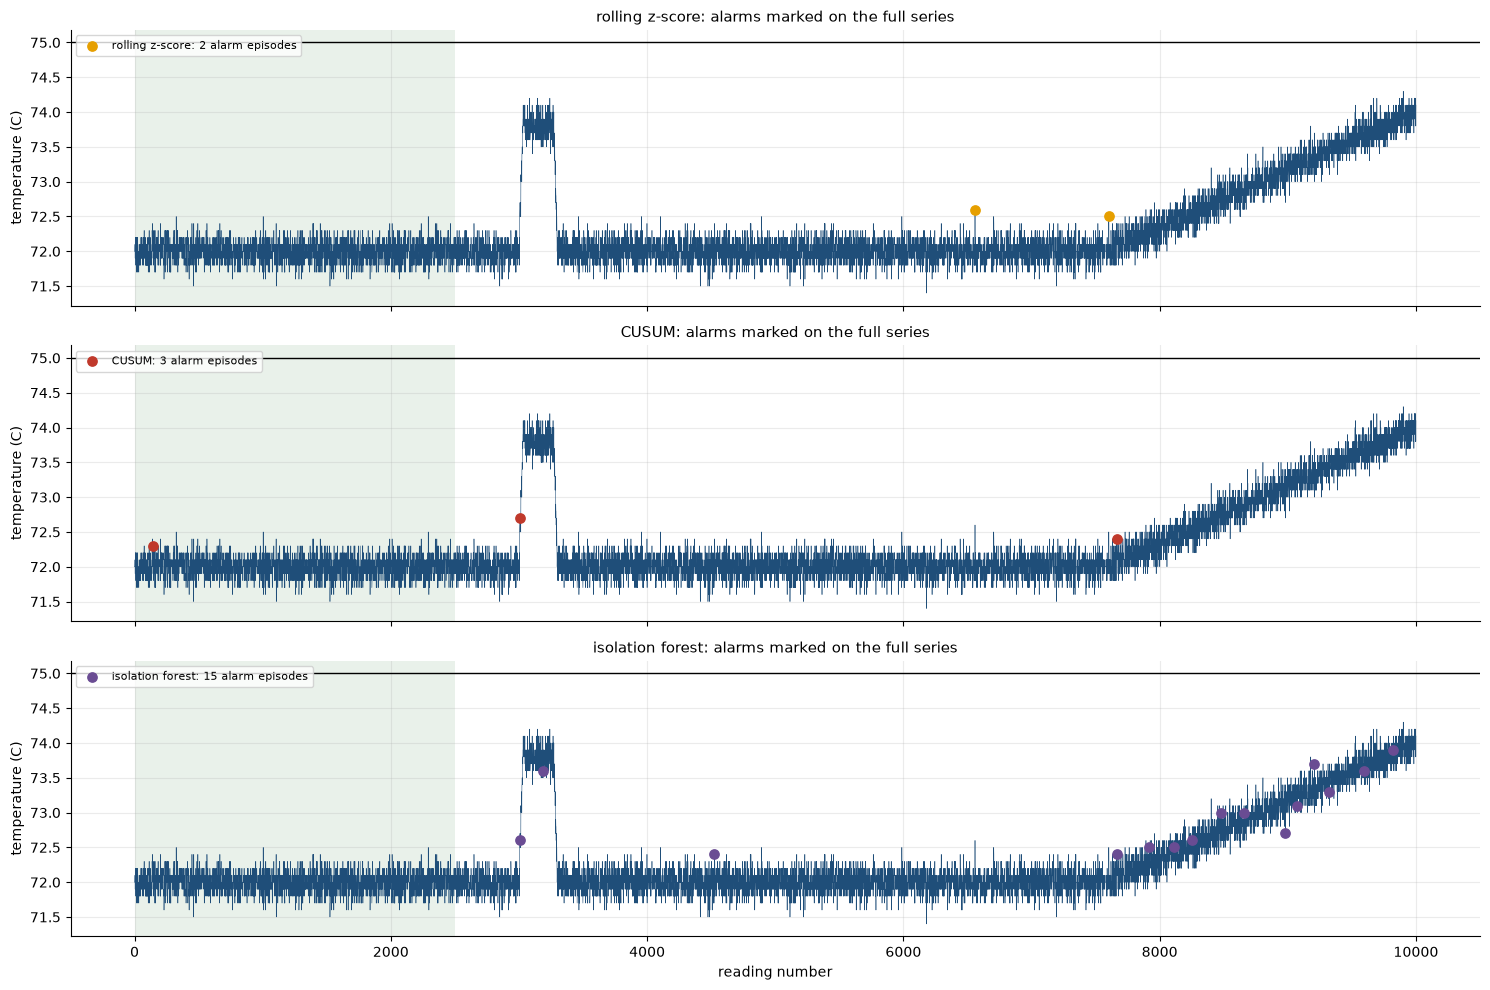

,alarm episodes,first alarm at reading,episodes inside the step,first alarm in the drift period,alarms before reading 2500 (false alarms),drift alarm: seconds after the drift began,reading at that alarm (C),minutes before the fitted line reaches 75 C
rolling z-score,2,6559,0,7603,0,3,72.5,59.62
CUSUM,3,144,1,7668,1,68,72.4,58.54
isolation forest,15,3010,2,7668,0,68,72.4,58.54


rolling z-score: alarm episodes start at readings [6559, 7603]
CUSUM: alarm episodes start at readings [144, 3008, 7668]
isolation forest: alarm episodes start at readings [3010, 3184, 4525, 7668, 7917, 8111, 8254, 8475, 8660, 8981, 9072, 9208, 9322, 9597, 9822]


In [27]:
# ---- apply the three detectors to the real 10,000 readings; mark what they find ----
x_row = x_temp[None, :]
a_z = episode_starts(np.abs(np.nan_to_num(rolling_zscore_2d(x_row, ZSCORE_WINDOW, 0.5 * SIG0))) > Z_THR)[0]
a_c_raw, stat_c = cusum_2d(x_row, MU0, SIG0, K_CUSUM, H_THR); a_c = episode_starts(a_c_raw)[0]
Fr, o = window_features(x_row, MU0); s_if = np.full(len(x_temp), np.nan); s_if[o:] = score(Fr)[0]; a_i = episode_starts((np.nan_to_num(s_if) > IF_THR)[None, :])[0]
found = {"rolling z-score": a_z, "CUSUM": a_c, "isolation forest": a_i}
t_ax = np.arange(1, len(x_temp) + 1)
fig, ax = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
for a, (nm, al), c in zip(ax, found.items(), (COL["amber"], COL["red"], COL["purple"])):
    a.plot(t_ax, x_temp, lw=0.4, color=COL["blue"]); a.axhline(T_USL, color="k", lw=1); a.axvspan(*BASELINE, color=COL["green"], alpha=0.10, lw=0)
    a.scatter(t_ax[al], x_temp[al], s=45, color=c, zorder=5, label=f"{nm}: {int(al.sum())} alarm episodes"); a.set(ylabel="temperature (C)"); a.legend(loc="upper left")
    a.set_title(f"{nm}: alarms marked on the full series")
ax[-1].set_xlabel("reading number"); plt.tight_layout(); plt.show()
first = {nm: (int(np.argmax(al)) + 1 if al.any() else None) for nm, al in found.items()}
def first_after(al, t0): idx = np.where(al & (t_ax >= t0))[0]; return int(idx[0]) + 1 if len(idx) else None
summ = pd.DataFrame({"alarm episodes": {nm: int(al.sum()) for nm, al in found.items()}, "first alarm at reading": first,
                     "episodes inside the step": {nm: int(al[ev_start - 61: ev_end + 60].sum()) for nm, al in found.items()},
                     "first alarm in the drift period": {nm: first_after(al, tb) for nm, al in found.items()},
                     "alarms before reading 2500 (false alarms)": {nm: int(al[:2500].sum()) for nm, al in found.items()}})
summ["drift alarm: seconds after the drift began"] = summ["first alarm in the drift period"] - tb
summ["reading at that alarm (C)"] = [x_temp[v - 1] if v else np.nan for v in summ["first alarm in the drift period"]]
summ["minutes before the fitted line reaches 75 C"] = [(breach_t - v) / 60 if v else np.nan for v in summ["first alarm in the drift period"]]
display(summ.round(2))
for nm, al in found.items(): print(f"{nm}: alarm episodes start at readings", (np.where(al)[0] + 1).tolist()[:20])
for nm, d in (("rolling z-score", "z"), ("CUSUM", "c"), ("isolation forest", "i")):
    KEY.update({f"real_{d}_n": int(summ.loc[nm, "alarm episodes"]), f"real_{d}_first": summ.loc[nm, "first alarm at reading"], f"real_{d}_drift": summ.loc[nm, "first alarm in the drift period"],
                f"real_{d}_early": float(summ.loc[nm, "reading at that alarm (C)"]), f"real_{d}_lead": float(summ.loc[nm, "minutes before the fitted line reaches 75 C"]),
                f"real_{d}_after": float(summ.loc[nm, "drift alarm: seconds after the drift began"]) if summ.loc[nm, "first alarm in the drift period"] else float("nan"),
                f"real_{d}_fa": int(summ.loc[nm, "alarms before reading 2500 (false alarms)"]), f"real_{d}_step": int(summ.loc[nm, "episodes inside the step"])})

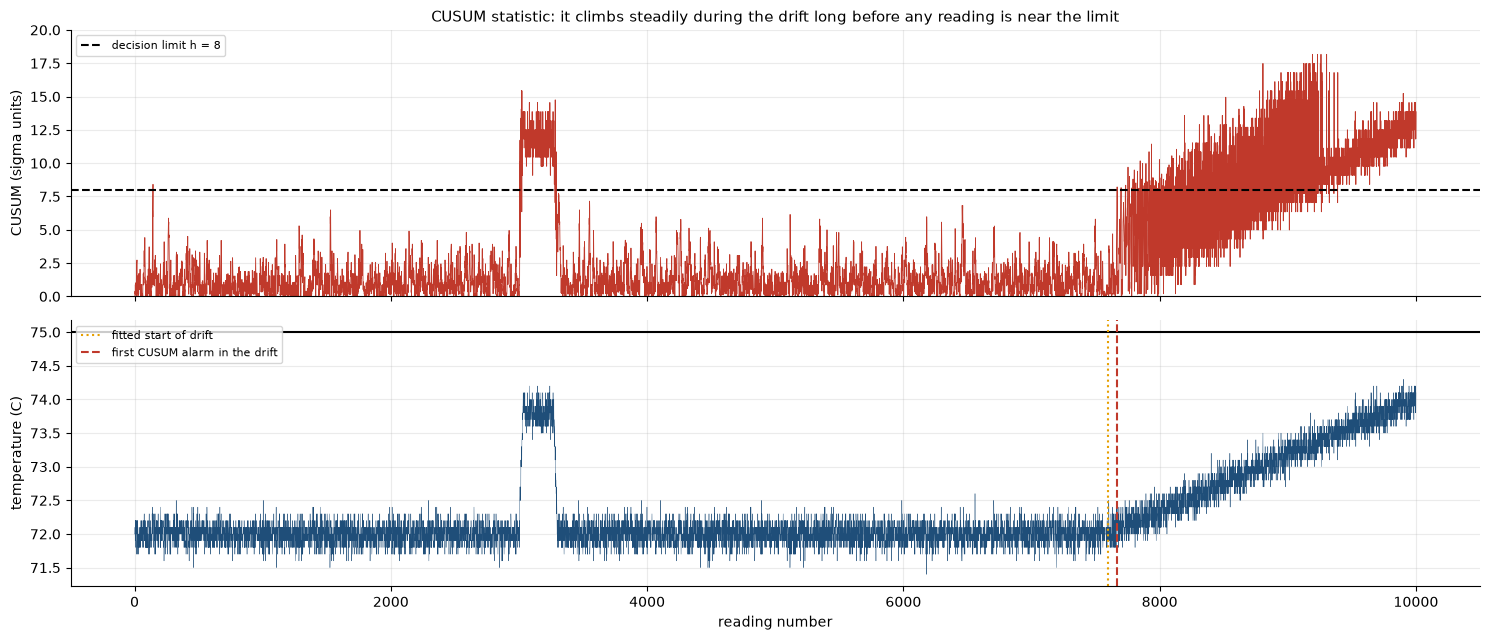

,level,trigger,who does what,response time
0,1 WARNING,"CUSUM alarm (small, sustained movement away fr...",Operator checks the sensor and the steam / hea...,within 10 min
1,2 ACTION,60-second mean at or beyond 73.0 C or 71.0 C (...,Supervisor and quality engineer attend; check ...,within 30 min
2,3 SHUTDOWN / HOLD,"60-second mean at or beyond 74.5 C or 70.5 C, ...","Stop the line, divert or hold product made sin...",immediately


first level-2 trigger at readings: [3048] | first level-2 trigger after the step ended: [8800] | level-3 triggers: 0
microseconds per reading: {'rolling z-score': 0.07, 'CUSUM': 14.65, 'isolation forest': 5.24}


In [28]:
# ---- the CUSUM statistic itself, and the tiered alert logic run on the real series ----
fig, ax = plt.subplots(2, 1, figsize=(15, 6.5), sharex=True)
ax[0].plot(t_ax, stat_c[0], lw=0.6, color=COL["red"]); ax[0].axhline(H_THR, color="k", ls="--", label=f"decision limit h = {H_THR:g}"); ax[0].set(ylabel="CUSUM (sigma units)", title="CUSUM statistic: it climbs steadily during the drift long before any reading is near the limit"); ax[0].legend()
ax[0].set_ylim(0, H_THR * 2.5)
ax[1].plot(t_ax, x_temp, lw=0.3, color=COL["blue"]); ax[1].axhline(T_USL, color="k"); ax[1].axvline(tb, color=COL["amber"], ls=":", label="fitted start of drift")
ax[1].axvline(KEY["real_c_drift"] or 0, color=COL["red"], ls="--", label="first CUSUM alarm in the drift"); ax[1].set(xlabel="reading number", ylabel="temperature (C)"); ax[1].legend(loc="upper left"); plt.tight_layout(); plt.show()

# Tiered alerts (thresholds are proposals for the quality manager to confirm)
LEVELS = pd.DataFrame([
    ["1  WARNING", "CUSUM alarm (small, sustained movement away from 72.0 C)", "Operator checks the sensor and the steam / heating valve settings; note it on the log", "within 10 min"],
    ["2  ACTION", "60-second mean at or beyond 73.0 C or 71.0 C (1 C from target)", "Supervisor and quality engineer attend; check sensor against a reference probe; hold product from the filler if the low side", "within 30 min"],
    ["3  SHUTDOWN / HOLD", "60-second mean at or beyond 74.5 C or 70.5 C, or any reading outside 70.0-75.0 C", "Stop the line, divert or hold product made since the last good check, call quality manager", "immediately"]],
    columns=["level", "trigger", "who does what", "response time"])
display(LEVELS)
m60 = pd.Series(x_temp).rolling(60).mean().to_numpy()
lv2 = (np.abs(m60 - T_TGT) >= 1.0); lv3 = (np.abs(m60 - T_TGT) >= 2.5) | (x_temp < T_LSL) | (x_temp > T_USL)
f2 = np.where(lv2)[0]; f3 = np.where(lv3)[0]
print("first level-2 trigger at readings:", f2[:1] + 1, "| first level-2 trigger after the step ended:", (f2[f2 > ev_end + 120][:1] + 1), "| level-3 triggers:", int(lv3.sum()))
KEY.update(lv2_first=int(f2[0]) + 1, lv2_drift=int(f2[f2 > ev_end + 120][0]) + 1, lv3_n=int(lv3.sum()))
KEY["lv2_drift_min_after_cusum"] = (KEY["lv2_drift"] - KEY["real_c_drift"]) / 60
KEY["lv2_drift_to_breach_min"] = (breach_t - KEY["lv2_drift"]) / 60
# run time (deployment cost)
tm = {}
for nm, fn in (("rolling z-score", lambda: rolling_zscore_2d(x_row, ZSCORE_WINDOW, 0.5 * SIG0)), ("CUSUM", lambda: cusum_2d(x_row, MU0, SIG0, K_CUSUM, H_THR)), ("isolation forest", lambda: score(window_features(x_row, MU0)[0]))):
    t0_ = time.perf_counter(); fn(); tm[nm] = (time.perf_counter() - t0_) / len(x_temp) * 1e6
print("microseconds per reading:", {k: round(v, 2) for k, v in tm.items()})
KEY.update(us_z=tm["rolling z-score"], us_c=tm["CUSUM"], us_i=tm["isolation forest"])

**Threshold against false alarms.** At the usual z-score threshold of 3 the 60-second z-score would raise about 12 false alarms an hour (10 in the real 41-minute baseline). The budget needs a threshold of **4.5** (0.10 per hour). For the CUSUM the textbook h of 4 or 5 gives about 17 or 8 false alarms an hour at one-second sampling, because the textbook values assume sparse samples; the budget needs **h = 8** (0.47 per hour). The isolation-forest score threshold is **0.2** (0.27 per hour).

**Detection performance (simulated faults, same budget).**

| fault | rolling z-score | CUSUM | isolation forest |
|---|---|---|---|
| small step, +0.3 C | 7% found in 1 h | 100% (median 4 s) | 100% (median 9 s) |
| +1.75 C over 35 s (like the recorded step) | 17% | 100% (median 8 s) | 100% (median 10 s) |
| slow drift at the observed rate | 10% | 100% (median 110 s) | 100% (median 262 s) |

The rolling z-score is nearly blind to both the 35-second rise and the drift: its 60-second window follows the change, so the change never looks unusual (this confirms hypothesis H2). The CUSUM and the isolation forest both catch everything within seconds to minutes, and the CUSUM is faster on the drift (median 110 s against 262 s).

**On the real series.** The CUSUM alarms at reading **7,668**, only 68 seconds after the fitted start of the drift, when the temperature is 72.4 C: about **59 minutes before the fitted drift line reaches 75 C**. It also alarms at reading 3,008, within seconds of the start of the step, and once at reading 144 inside the baseline window (one false alarm, within the allowance of two). During the drift the CUSUM keeps re-triggering, with gaps always shorter than 60 seconds, so the 60-second rule counts it as one continuing alarm episode rather than over a thousand separate alarms. The rolling z-score raises two isolated alarms (readings 6,559 and 7,603), neither tied to the step or to a sustained drift: it missed both events. The isolation forest finds the step and the start of the drift but then keeps re-alarming (15 alarm episodes in total, one at reading 4,525 in a quiet stretch), which would train operators to ignore it. Run time is negligible for all three (microseconds per reading: z-score 0.07, CUSUM 14.7, forest 5.2), so latency is not a constraint: the CUSUM needs only two running numbers per sensor and could run on a plant controller.

**A tiered alert plan (proposal).** The three levels in the table above attach a consequence to each trigger. On the real data, level 1 (CUSUM) fires at reading 7,668, level 2 (60-second mean 1 C from target) first fires at reading 8,800 in the drift, about 19 minutes after the CUSUM, and level 3 never fires (0 readings). The step triggers level 2 at reading 3048. This is the margin the CUSUM buys: roughly 59 minutes between the first warning and the (extrapolated) breach, against about 40 minutes from the level-2 trigger.

*Caution on cause.* A rising temperature reading is consistent with several things (a failing temperature sensor, a heating or control fault, or a change in flow or heat transfer such as fouling in the exchanger). The data cannot tell which; the detector only says that something has changed and when. If the sensor is reading high while the true temperature is falling, the risk is under-pasteurisation, so the first response to any alarm is to compare the sensor with an independent reference probe.

### 7.6 Which detector and threshold I would run (DRAFT: rewrite in your own words)

**I would run the CUSUM with k = 0.5 and h = 8**, baseline mean 72.00 C and sigma 0.146 C. On the simulation it was the only one of the three that found all three kinds of fault quickly without the false-alarm rate going above the budget of 0.5 per hour (it found the drift in a median of about 110 seconds). On the real data it flagged the drift at 72.4 C, roughly an hour before the fitted line would reach the limit. The rolling z-score misses the drift entirely, and the isolation forest raised repeated alarms during the drift, which makes it a poor operator tool (though it could be useful as a second opinion for the data team).

I would use the tiered levels above, with the CUSUM as the **warning** (operator checks the sensor), a 60-second mean 1 C from target as the **action** (supervisor and quality engineer) and a 60-second mean 2.5 C from target or any reading outside 70 to 75 C as the **hold or shutdown** level. The sensitivity is a choice: a higher h gives fewer false alarms and a later warning; I would revisit h after a month of live data. Limitation: the threshold was tuned on 41 minutes of real baseline plus simulated noise, so the true false-alarm rate on the live line must be checked.

<a id="s8"></a>
## 8. Recommendations for the quality manager

### 8.1 What I found, in plain words (DRAFT: rewrite in your own words)

* **The pasteuriser temperature drifted upwards and nobody would have seen it.** For the first 40 minutes the temperature held at 72 C within about half a degree. A temporary jump of about 1.8 C lasted just under five minutes, and from about the 2 hour 07 minute mark the temperature rose steadily at about 3 C per hour, to 74.3 C by the end of the record. Every single reading stayed inside the 70 to 75 C limits, so a check against the limits alone would have raised nothing. If the rise had gone on, it would have crossed 75 C roughly 20 minutes after the record ended.
* **The fill process is stable but only just good enough, and it leans heavy.** The average bottle holds 500.9 ml against a 500 ml target, and about 7 bottles in 1,000 in the sample were over the 510 ml limit (none under 490 ml). Its capability score (Cpk 0.97) is just under 1, below the 1.33 that most customers expect.

### 8.2 What I recommend

1. **Check the temperature sensor and the pasteuriser heating control now** (this week). Compare the sensor against a calibrated reference thermometer, then inspect the heat exchanger and the heating valve. Do not wait for 75 C: the alarm is the change, not the limit.
2. **Switch on the automated temperature alert.** Warn the operator when the cumulative-sum alert triggers (settings: 8 sigma units, tuned to at most one false alarm every two hours); call the supervisor and quality engineer when the one-minute average is 1 C away from 72 C; stop the line and hold product when it is 2.5 C away, or any reading is outside 70 to 75 C. Review the settings after a month of live data.
3. **Use the quiet stretch as the reference for the temperature chart** (centre 72.00 C, action limits 71.56 to 72.44 C), and refit it after maintenance on a fresh, steady stretch. Do not refit it on a run that includes a fault; it will hide the fault.
4. **Cut the filler's variation and re-centre it.** Aim to reduce the filler's own variation by about 20% (from 3.1 to about 2.5 ml) and bring the average down towards 500 ml, which recovers about 91 litres of product per 100,000 bottles and brings Cpk to about 1.33. Agree the new setpoint with quality and compliance first: moving the average down only makes sense once the spread is smaller, so that the underfill risk does not grow.
5. **Look into the occasional overfills and the operator difference.** Subgroups 125 and 128 (including a 513.5 ml bottle) and the high-range subgroup 48 are worth checking against the filler logs. Bottles filled during operator MB's run averaged 0.6 ml more than during PN's, which points to a set-up difference at handover.
6. **Report two numbers every shift:** the fill Cpk (target 1.33) and the number of temperature alerts, with a short note of what was done.

### 8.3 What automated monitoring gives you that paper checks did not

* **Coverage.** The sensor takes 3,600 readings an hour; a paper check takes a handful. In this record the temperature rose about 2 C without any reading touching a limit, and a person looking at individual numbers inside the limits would have had no reason to worry.
* **Speed.** The warning came about 68 seconds after the drift began, around an hour before the extrapolated breach, instead of at the next check (or never).
* **Consistency and a record.** The same arithmetic runs for every shift and nobody has to interpret a chart at 3 a.m.; every alert is time-stamped for the batch record and for any later audit (PPB, EFDA, EFSA or FDA).
* **A caution.** Automation also makes false alarms cheap to create. The alert levels and the false-alarm budget are what keep operators trusting it, so they need an owner and a monthly review.

<a id="s9"></a>
## 9. What this notebook does not do

* **Not built (stretch goals):** an interactive dashboard (ipywidgets or Panel), interactive plotly charts, and a cost comparison of automated monitoring against the paper system. The data hold no cost information, so costs have not been guessed.
* **One short run.** The temperature record is 2 hours 46 minutes from one sensor and the fill record about 33 hours; neither shows day-to-day or seasonal variation. The false-alarm rates for the detectors come from simulated noise matched to the baseline window and should be checked on live data.
* **Causes are hypotheses.** The data say when the temperature changed and by how much, not why. Any statement about fouling, sensor drift or valve faults is something to check, not a finding.
* **Reproducibility.** The notebook is deterministic (fixed seed, no random choices outside it) and reads its two files by bare name, so it runs unchanged in Google Colab once the CSVs are uploaded beside it.

### Figures quoted in this notebook
The cell below prints the dictionary behind every number in the text.

In [29]:
# last cell: every figure the narrative quotes, printed so the text can be checked against the code
def clean(v):
    if isinstance(v, (np.floating, float)): return None if np.isnan(v) else float(v)
    if isinstance(v, (np.integer,)): return int(v)
    return v
print(json.dumps({k: clean(v) for k, v in KEY.items()}, default=str))

{"t_rows": 10000, "f_rows": 1000, "f_groups": 200, "t_dups": 0, "t_missing": 0, "f_missing": 0, "t_gaps": 0, "t_max": 74.3, "t_min": 71.4, "f_over": 7, "f_under": 0, "t_hours": 2.7777777777777777, "base_mu": 71.99804, "base_sd": 0.14905383328880512, "ev_start": 3014, "ev_end": 3289, "ev_len": 276, "ev_level": 73.78697674418603, "drift_start": 7600, "drift_slope_hr": 3.017920350363546, "drift_slope_s": 0.0008383112084343183, "breach_t": 11180.393423199272, "breach_after_min": 19.67322371998786, "acf1_base": -0.008095235894504272, "acf1_all": 0.9338551024212886, "acf10_all": 0.9305971916092727, "n_blocks_steady": 14, "f_op_diff": 0.6334687500000769, "f_pos_p": 0.1355993936726031, "f_r_xbar_R": 0.09710007413130275, "f_op_p": 0.003043145282233098, "f_op_range_p": 0.37946993653392763, "f_pn_mean": 500.68578125, "f_mb_mean": 501.31925000000007, "f_slope_p": 0.14487534971268715, "f_acf1": 0.002846902508661946, "f_mean": 500.91382999999996, "f_sd": 3.1571957043895487, "f_skew": 0.1378729849340